In [10]:
import pandas as pd
import numpy as np

### Exploratory Data Analysis

#### Understanding the Data

In [7]:
df = pd.read_csv("credit_card_fraud_2026.csv")
df.head()

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0,3.9,2,4,False,32.7,0,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   transaction_id                20000 non-null  int64  
 1   amount_usd                    20000 non-null  float64
 2   merchant_category             20000 non-null  str    
 3   card_type                     20000 non-null  str    
 4   auth_method                   20000 non-null  str    
 5   channel                       20000 non-null  str    
 6   device_type                   20000 non-null  str    
 7   is_foreign_transaction        20000 non-null  bool   
 8   hours_since_last_txn          20000 non-null  float64
 9   txn_count_last_24h            20000 non-null  int64  
 10  distance_from_home_km         20000 non-null  float64
 11  card_age_months               20000 non-null  int64  
 12  customer_age                  20000 non-null  int64  
 13  account_bala

In [5]:
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values:
 transaction_id                  0
amount_usd                      0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
is_ai_generated_scam_attempt    0
merchant_risk_score             0
prior_disputes                  0
is_fraud                        0
dtype: int64
Duplicate rows: 0


In [6]:
import matplotlib.pyplot as plt
import pandas as pd

# Define your target column name based on your split
TARGET = 'is_fraud'

# Combine X_train and y_train for safe training-set analysis
train_df = X_train.copy()
train_df[TARGET] = y_train

# Calculate baseline fraud rate strictly from the training split
rate = y_train.mean()

# Plotting volume vs fraud % by hour and day of week
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, col, title in [(axes[0], "time_of_day_hour", "Hour of day"), (axes[1], "day_of_week", "Day of week (0 = Monday)")]:
    g = train_df.groupby(col)[TARGET].agg(["mean", "size"])
    ax.bar(g.index, g["size"], color="#4C72B0", alpha=.55)
    ax.set_ylabel("volume")
    ax.set_xlabel(col)
    ax2 = ax.twinx()
    ax2.plot(g.index, g["mean"] * 100, "o-", c="#C44E52")
    ax2.set_ylabel("fraud %")
    ax2.axhline(rate * 100, ls="--", c="k", lw=1)
    ax.set_title(f"{title}: volume vs fraud %")

plt.tight_layout()
plt.show()

# Statistical breakdown
hr = train_df.groupby("time_of_day_hour")[TARGET].mean()
dw = train_df.groupby("day_of_week")[TARGET].mean()

print(f"hour of day : peak {hr.idxmax()}h at {hr.max():.2%} = {hr.max() / rate:.2f}x baseline | lowest {hr.idxmin()}h = {hr.min() / rate:.2f}x")
print(
    f"day of week : max {dw.max() / rate:.2f}x | min {dw.min() / rate:.2f}x baseline")
print("=> " + ("the clock effect is essentially flat in this data - time features will matter little" if hr.max() / rate < 1.3
               else "there is a real time-of-day effect - worth explicit time features"))

NameError: name 'X_train' is not defined

#### Correlation Heatmap

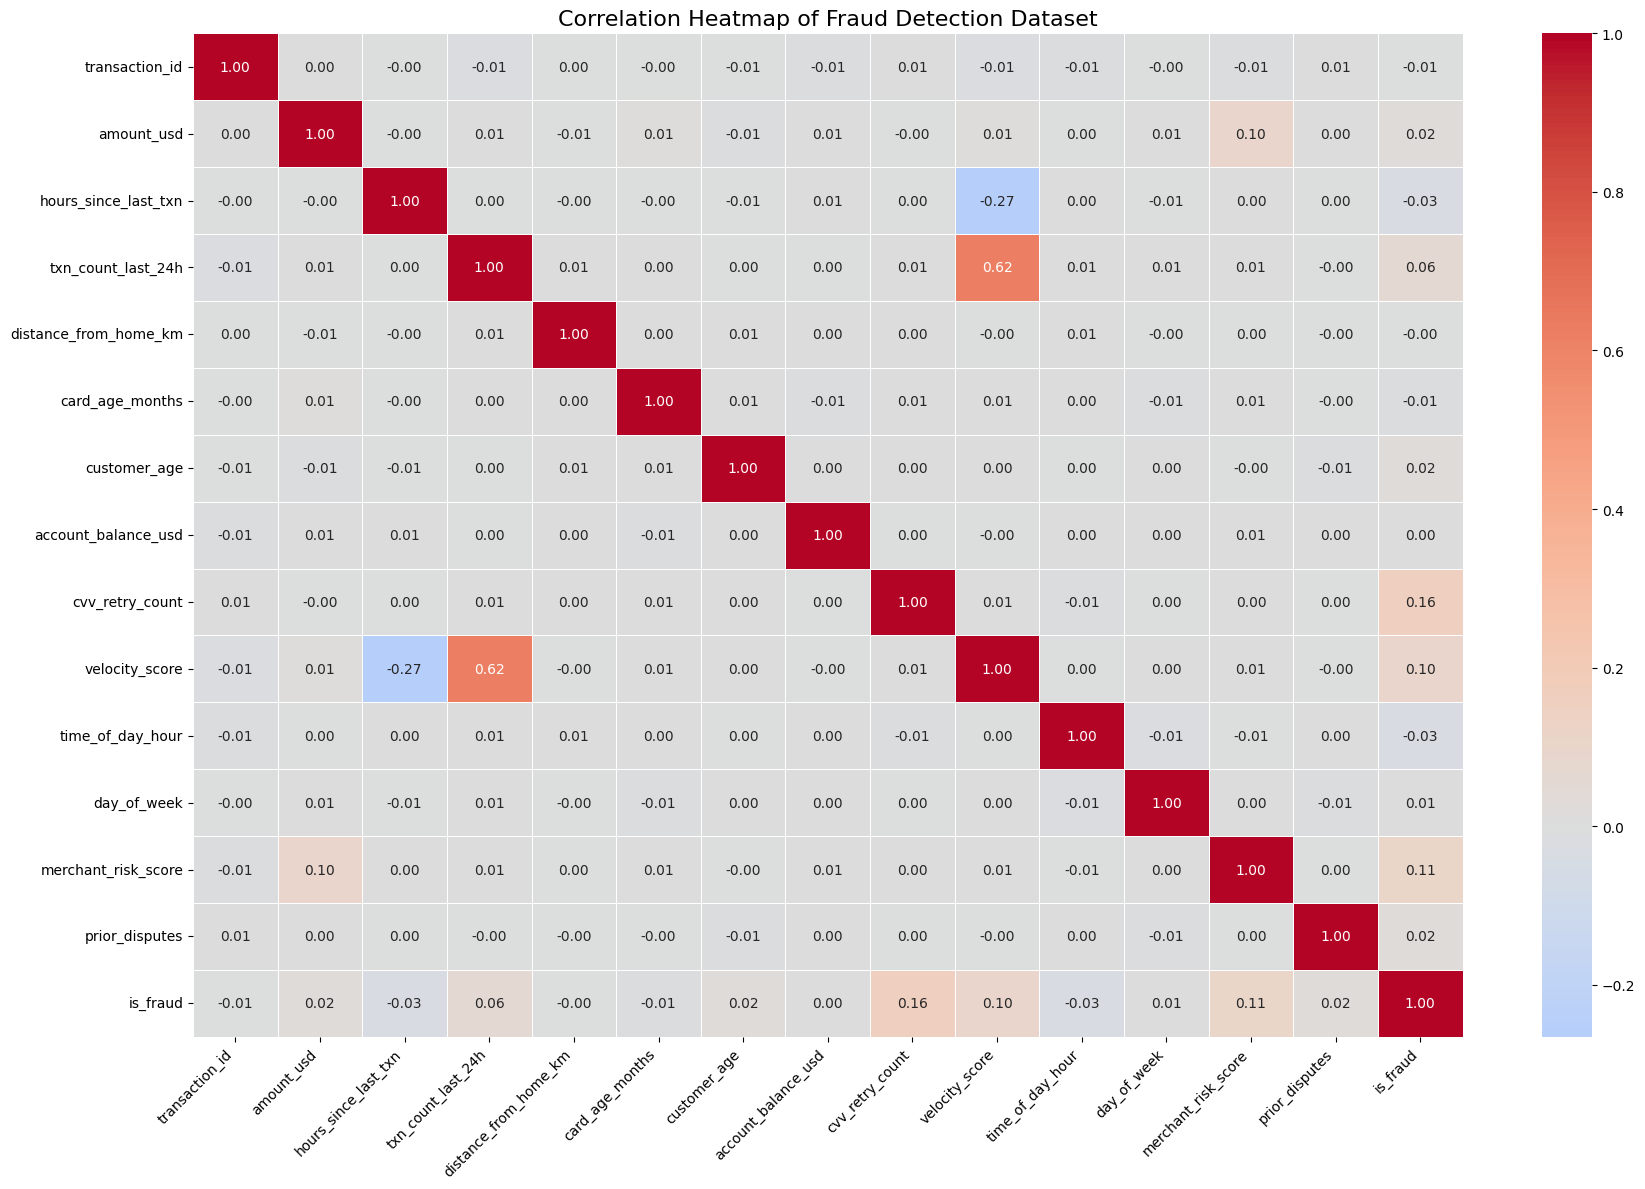

In [ ]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns only
numerical_data = df.select_dtypes(include=['int64', 'float64'])

# Calculate correlation matrix
corr_matrix = numerical_data.corr()

# Plot heatmap
plt.figure(figsize=(18, 12))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Heatmap of Fraud Detection Dataset', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


#### Class Imbalance

Fraud rate: 1.70%  (339 of 20000)
Accuracy of a "never fraud" model: 98.30%  <-- catches ZERO fraud


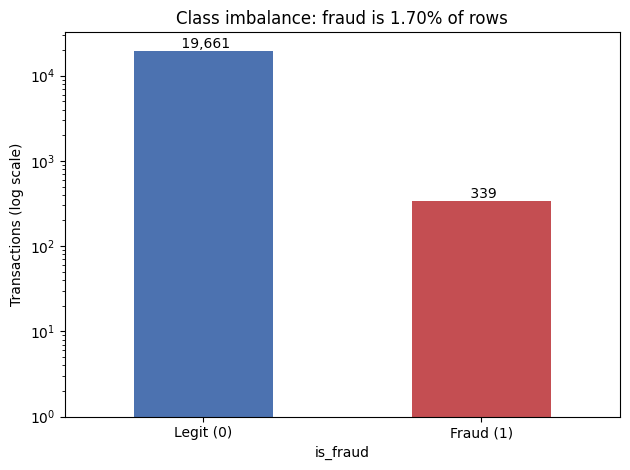

In [ ]:
rate = df['is_fraud'].mean()
print(f'Fraud rate: {rate*100:.2f}%  ({df.is_fraud.sum()} of {len(df)})')
print(
    f'Accuracy of a "never fraud" model: {(1-rate)*100:.2f}%  <-- catches ZERO fraud')

counts = df['is_fraud'].value_counts().sort_index()
ax = counts.plot(kind='bar', color=['#4C72B0', '#C44E52'], log=True)
ax.set_xticklabels(['Legit (0)', 'Fraud (1)'], rotation=0)
ax.set_ylabel('Transactions (log scale)')
ax.set_title(f'Class imbalance: fraud is {rate*100:.2f}% of rows')
for i, v in enumerate(counts):
    ax.text(i, v, f' {v:,}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

### Test-Train Split

#### 80-20 Split

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Separate features (X) and target (y)
X = df.drop(columns=['transaction_id', 'is_fraud'])
y = df['is_fraud']

# 2. Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,       # Holds out 20% of data for final testing
    random_state=42,     # Ensures reproducibility
    stratify=y           # Crucial for fraud: keeps the exact same % of fraud cases in train and test
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Fraud percentage in training set: {y_train.mean():.4%}")
print(f"Fraud percentage in testing set: {y_test.mean():.4%}")

Training set shape: (16000, 24)
Testing set shape: (4000, 24)
Fraud percentage in training set: 1.6938%
Fraud percentage in testing set: 1.7000%


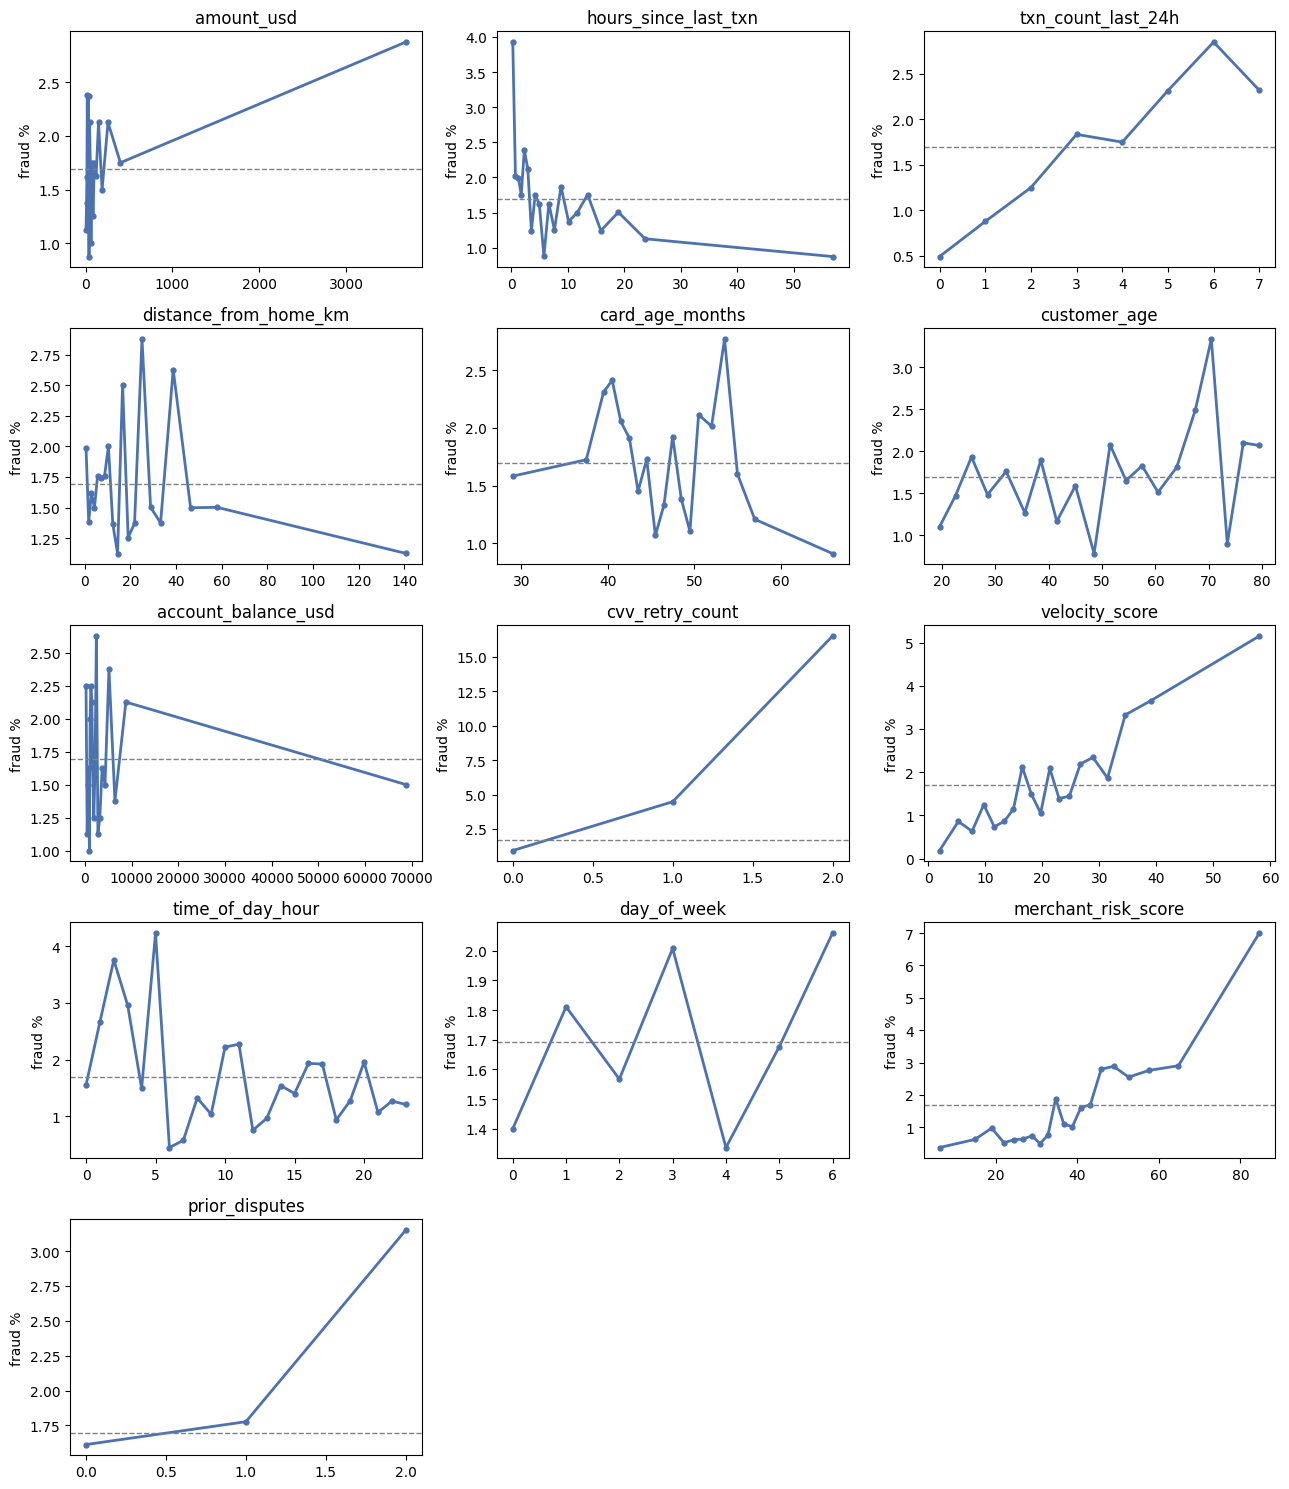

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 0. Define safe fallbacks for constants if not already defined in your notebook
TARGET = globals().get('TARGET', 'is_fraud')
C_TRAIN = globals().get('C_TRAIN', '#4C72B0')

# Ensure train dataframe is available
if 'train' not in globals():
    train = X_train.copy()
    train[TARGET] = y_train

base = train[TARGET].mean()

# Automatically infer NUM and LOG columns if they aren't defined in your session
if 'NUM' not in globals():
    NUM = list(train.select_dtypes(include=[np.number]).columns.drop(
        TARGET, errors='ignore'))[:15]

if 'LOG' not in globals():
    LOG = []  # Add column names here that need a log scale if desired

# 1. Helper function to compute binned or exact fraud rates


def fraud_rate_by(df, c, q=20):
    x = df[c]
    key = x if x.nunique() <= 30 else pd.qcut(
        x, q, duplicates="drop").apply(lambda iv: iv.mid)
    g = df.groupby(key, observed=True)[TARGET].agg(["mean", "size"])
    return g[g["size"] >= 200]


# 2. Plotting grid for numerical features
fig, axes = plt.subplots(5, 3, figsize=(13, 15))

for ax, c in zip(axes.flat, NUM):
    g = fraud_rate_by(train, c)
    ax.plot(g.index.astype(float), g["mean"] * 100,
            marker="o", ms=3.5, lw=2, color=C_TRAIN)
    ax.axhline(base * 100, ls="--", lw=1, color="grey")
    ax.set_title(c)
    ax.set_ylabel("fraud %")
    if c in LOG:
        ax.set_xscale("log")

# Turn off any unused subplots in the grid
for ax in axes.flat[len(NUM):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

cvv_retry_count is the clearest signal: each failed CVV attempt pushes the fraud rate up sharply. merchant_risk_score and velocity_score rise steadily, as expected. More transactions in the last 24h, or a very short gap since the last transaction, also mean more fraud. customer_age has a visible pattern too. Distance, card age, balance, hour and weekday look flat on their own.

#### StratifiedKFold on Training Data

In [13]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

y_train_arr = np.asarray(y_train, dtype=int)

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train_arr), start=1):
    X_tr = X_train.iloc[train_idx]
    y_tr = y_train_arr[train_idx]
    X_va = X_train.iloc[val_idx]
    y_va = y_train_arr[val_idx]

    print(
        f"Fold {fold}: train={len(train_idx)} rows (fraud={y_tr.mean():.4%}), "
        f"val={len(val_idx)} rows (fraud={y_va.mean():.4%})"
    )

Fold 1: train=12800 rows (fraud=1.6953%), val=3200 rows (fraud=1.6875%)
Fold 2: train=12800 rows (fraud=1.6953%), val=3200 rows (fraud=1.6875%)
Fold 3: train=12800 rows (fraud=1.6953%), val=3200 rows (fraud=1.6875%)
Fold 4: train=12800 rows (fraud=1.6953%), val=3200 rows (fraud=1.6875%)
Fold 5: train=12800 rows (fraud=1.6875%), val=3200 rows (fraud=1.7188%)


### Encoding Categorical Variables

In [ ]:
# Define your categorical columns
categorical_cols = [
    'merchant_category', 
    'card_type', 
    'auth_method', 
    'channel', 
    'device_type'
]

# Loop through each categorical column and print unique values & counts
for col in categorical_cols:
    if col in df.columns:
        print(f"=== {col} ({df[col].nunique()} unique values) ===")
        print(df[col].value_counts(dropna=False))
        print("\n" + "-"*40 + "\n")

=== merchant_category (12 unique values) ===
merchant_category
Online Retail      3416
Groceries          3242
Restaurants        2534
Electronics        2032
Fuel               1565
Travel             1420
Utilities          1330
Healthcare         1237
Gaming             1036
Streaming          1010
Gift Cards          617
Crypto Exchange     561
Name: count, dtype: int64

----------------------------------------

=== card_type (5 unique values) ===
card_type
Visa          8417
Mastercard    6629
Amex          2135
RuPay         1796
Discover      1023
Name: count, dtype: int64

----------------------------------------

=== auth_method (5 unique values) ===
auth_method
3D Secure            5554
OTP                  4792
PIN                  4173
Biometric            3093
No Authentication    2388
Name: count, dtype: int64

----------------------------------------

=== channel (5 unique values) ===
channel
Online         6810
POS            5191
Contactless    3400
In-App         3225

In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. Define your categorical columns
categorical_cols = [
    'merchant_category', 
    'card_type', 
    'auth_method', 
    'channel', 
    'device_type'
]

# Numerical/Boolean columns are everything else
numerical_cols = [col for col in X_train.columns if col not in categorical_cols]

# 2. Set up the ColumnTransformer for One-Hot Encoding
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_cols)
    ],
    remainder='passthrough' # Keeps numerical and boolean columns untouched
)

# 3. Fit on X_train ONLY, then transform both X_train and X_test
X_train_array = preprocessor.fit_transform(X_train)
X_test_array = preprocessor.transform(X_test)

# 4. Extract final feature names
encoded_cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_feature_names = list(encoded_cat_names) + numerical_cols

# 5. Convert back to DataFrames and cast everything to float
X_train_encoded = pd.DataFrame(X_train_array, columns=all_feature_names, index=X_train.index).astype(float)
X_test_encoded = pd.DataFrame(X_test_array, columns=all_feature_names, index=X_test.index).astype(float)

print(f"✅ Encoding complete!")
print(f"X_train_encoded shape: {X_train_encoded.shape}")
print(f"X_test_encoded shape: {X_test_encoded.shape}")
print(f"Data type check: All columns are now numeric ({X_train_encoded.dtypes.nunique() == 1})")

✅ Encoding complete!
X_train_encoded shape: (16000, 49)
X_test_encoded shape: (4000, 49)
Data type check: All columns are now numeric (True)


#### Mitigating Class Imbalance

In [ ]:
# Calculate scale_pos_weight for XGBoost and LightGBM
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_value = neg_count / pos_count

print(f"Negative (Legit) samples: {neg_count}")
print(f"Positive (Fraud) samples: {pos_count}")
print(f"Calculated scale_pos_weight: {scale_pos_weight_value:.2f}")

Negative (Legit) samples: 15729
Positive (Fraud) samples: 271
Calculated scale_pos_weight: 58.04


### Fitting the Models

#### 1. Random forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve, auc

# 1. Initialize Random Forest
# class_weight='balanced' automatically adjusts weights inversely proportional to class frequencies
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,          # Limits depth to prevent overfitting on tabular data
    class_weight='balanced', # Handles the severe class imbalance
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest model...")
rf_model.fit(X_train_encoded, y_train)

# 2. Predict classes and probabilities on the test set
y_pred = rf_model.predict(X_test_encoded)
y_pred_proba = rf_model.predict_proba(X_test_encoded)[:, 1]

# 3. Generate Confusion Matrix
print("\n--- Confusion Matrix ---")
cm = confusion_matrix(y_test, y_pred)
print(cm)
print("\nLayout: [[True Negatives, False Positives],")
print("         [False Negatives, True Positives]]")

# 4. Generate Classification Report
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

# 5. Calculate AUC Metrics
roc_auc = roc_auc_score(y_test, y_pred_proba)
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
pr_auc = auc(recall, precision)

print(f"Test ROC-AUC Score: {roc_auc:.4f}")
print(f"Test PR-AUC Score: {pr_auc:.4f}")

Training Random Forest model...

--- Confusion Matrix ---
[[3902   30]
 [  60    8]]

Layout: [[True Negatives, False Positives],
         [False Negatives, True Positives]]

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      3932
           1       0.21      0.12      0.15        68

    accuracy                           0.98      4000
   macro avg       0.60      0.56      0.57      4000
weighted avg       0.97      0.98      0.97      4000

Test ROC-AUC Score: 0.9001
Test PR-AUC Score: 0.1492


In [ ]:
import numpy as np
from sklearn.metrics import precision_recall_curve, confusion_matrix, classification_report

# 1. Get predicted probabilities for the fraud class (class 1)
y_scores = rf_model.predict_proba(X_test_encoded)[:, 1]

# 2. Compute precision, recall, and thresholds from the curve
precisions, recalls, thresholds = precision_recall_curve(y_test, y_scores)

# 3. Calculate F1-score for every possible threshold (handling potential division by zero)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)

# 4. Find the threshold that yields the maximum F1-score
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f" Optimal Threshold for Best F1-Score: {best_threshold:.4f}")

# 5. Apply this new custom threshold to make predictions
y_pred_optimized = (y_scores >= best_threshold).astype(int)

# 6. Evaluate with the new threshold
print("\n--- Optimized Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_optimized))

print("\n--- Optimized Classification Report ---")
print(classification_report(y_test, y_pred_optimized))

 Optimal Threshold for Best F1-Score: 0.4096

--- Optimized Confusion Matrix ---
[[3858   74]
 [  49   19]]

--- Optimized Classification Report ---
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      3932
           1       0.20      0.28      0.24        68

    accuracy                           0.97      4000
   macro avg       0.60      0.63      0.61      4000
weighted avg       0.97      0.97      0.97      4000



##### Feature Importance

--- Random Forest Top 10 Feature Importances ---


,Feature,Importance
0,merchant_risk_score,0.128944
1,cvv_retry_count,0.122816
2,velocity_score,0.091851
3,ip_country_mismatch,0.073954
4,auth_method_No Authentication,0.048874
5,hours_since_last_txn,0.044054
6,is_new_merchant,0.040323
7,billing_shipping_mismatch,0.039471
8,amount_usd,0.034230
9,time_of_day_hour,0.033416


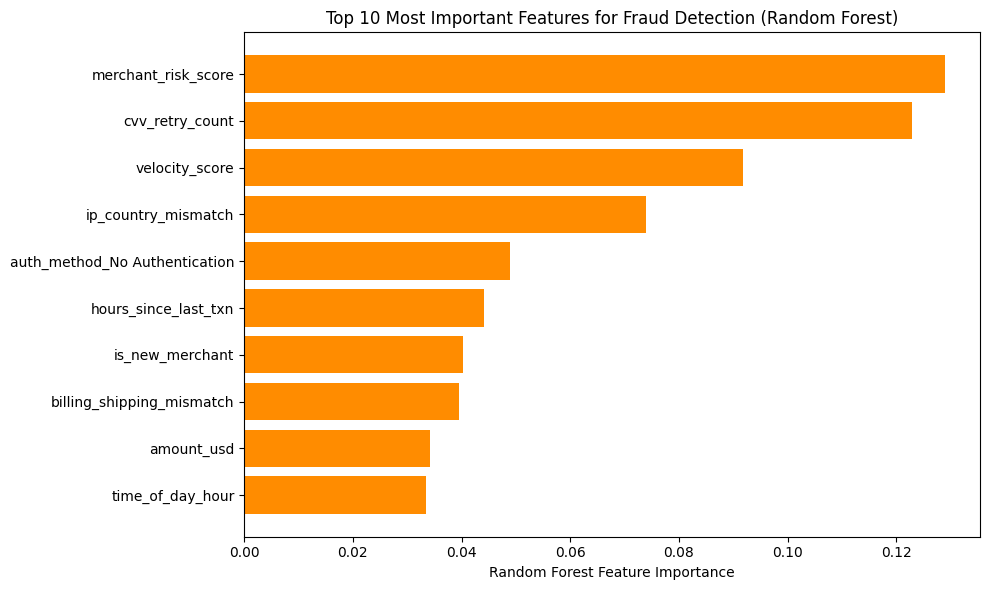

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Get feature names from the preprocessor & importances
feature_names = preprocessor.get_feature_names_out()
importances = rf_model.feature_importances_

# 2. Create a dataframe and clean up names
rf_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

rf_imp_df['Feature'] = rf_imp_df['Feature'].str.replace(
    r'^(cat__|bool__|remainder__)', '', regex=True)

# 3. Display the top 10 as a table
print("--- Random Forest Top 10 Feature Importances ---")
display(rf_imp_df.head(10))

# 4. Plot top 10
plt.figure(figsize=(10, 6))
top_rf = rf_imp_df.head(10)
plt.barh(top_rf['Feature'][::-1], top_rf['Importance']
         [::-1], color='darkorange')
plt.xlabel("Random Forest Feature Importance")
plt.title("Top 10 Most Important Features for Fraud Detection (Random Forest)")
plt.tight_layout()
plt.show()

##### ROC-AUC curve

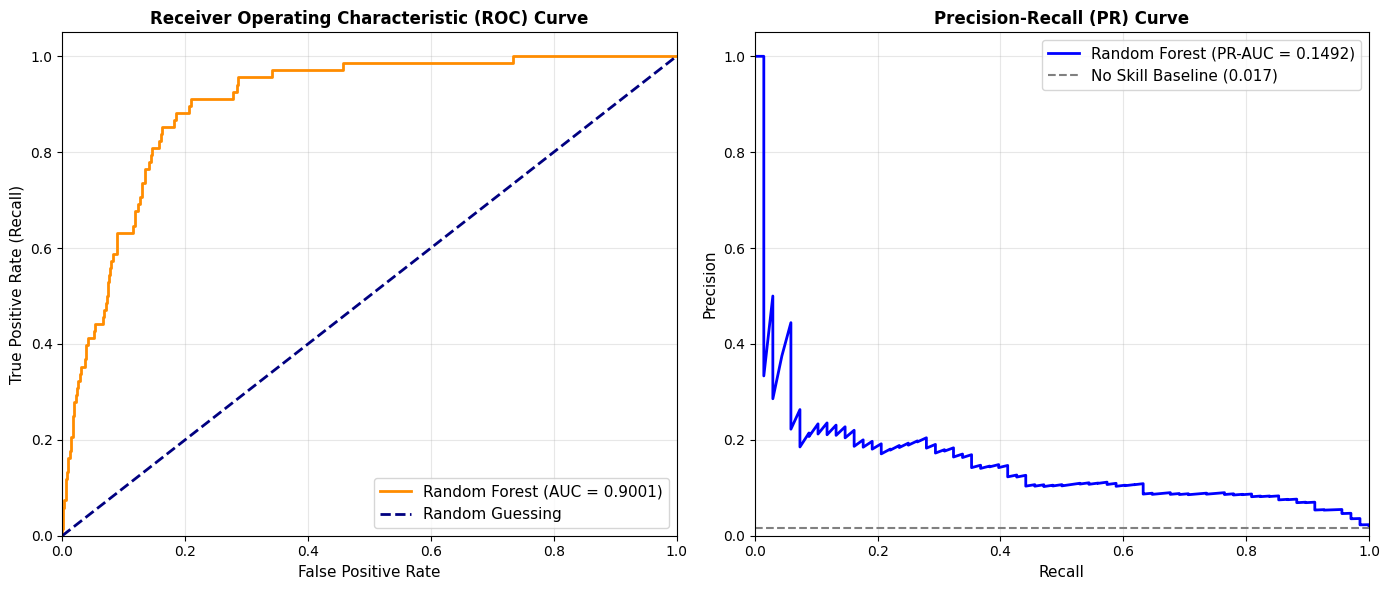

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc

# 1. Get predicted probabilities for the positive class (fraud)
y_pred_proba_rf = rf_model.predict_proba(X_test_encoded)[:, 1]

# 2. Compute ROC curve and AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_proba_rf)
roc_auc = auc(fpr, tpr)

# 3. Compute Precision-Recall curve and AUC
precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba_rf)
pr_auc = auc(recall, precision)

# 4. Plot both curves side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Plot 1: ROC Curve ---
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'Random Forest (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate (Recall)', fontsize=11)
axes[0].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=12, fontweight='bold')
axes[0].legend(loc="lower right", fontsize=11)
axes[0].grid(alpha=0.3)

# --- Plot 2: Precision-Recall Curve ---
axes[1].plot(recall, precision, color='blue', lw=2, label=f'Random Forest (PR-AUC = {pr_auc:.4f})')
# Baseline for PR curve is the ratio of positive samples in y_test
no_skill = y_test.sum() / len(y_test)
axes[1].axhline(y=no_skill, color='gray', linestyle='--', label=f'No Skill Baseline ({no_skill:.3f})')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title('Precision-Recall (PR) Curve', fontsize=12, fontweight='bold')
axes[1].legend(loc="upper right", fontsize=11)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 2. XGBoost

In [ ]:
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve, auc
import numpy as np

# 1. Initialize XGBoost with your scale_pos_weight for class imbalance
xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=6,
    scale_pos_weight=58.04, # Balances the 1.7% fraud ratio natively
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost model...")
xgb_model.fit(X_train_encoded, y_train)

# 2. Predict probabilities on the test set
y_pred_proba_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]

# 3. Calculate AUC Metrics
roc_auc_xgb = roc_auc_score(y_test, y_pred_proba_xgb)
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba_xgb)
pr_auc_xgb = auc(recalls, precisions)

print(f"\n--- XGBoost Performance ---")
print(f"Test ROC-AUC Score: {roc_auc_xgb:.4f}")
print(f"Test PR-AUC Score: {pr_auc_xgb:.4f}")

# 4. Find the optimal F1 threshold for XGBoost
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold_xgb = thresholds[best_idx]

print(f"Optimal Threshold for Best F1-Score: {best_threshold_xgb:.4f}")

# 5. Evaluate at the optimized threshold
y_pred_xgb_optimized = (y_pred_proba_xgb >= best_threshold_xgb).astype(int)

print("\n--- XGBoost Optimized Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_xgb_optimized))

print("\n--- XGBoost Optimized Classification Report ---")
print(classification_report(y_test, y_pred_xgb_optimized))

Training XGBoost model...

--- XGBoost Performance ---
Test ROC-AUC Score: 0.8703
Test PR-AUC Score: 0.2154
Optimal Threshold for Best F1-Score: 0.3841

--- XGBoost Optimized Confusion Matrix ---
[[3876   56]
 [  46   22]]

--- XGBoost Optimized Classification Report ---
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3932
           1       0.28      0.32      0.30        68

    accuracy                           0.97      4000
   macro avg       0.64      0.65      0.64      4000
weighted avg       0.98      0.97      0.98      4000



##### Feature importance

--- XGBoost Top 10 Feature Importances ---
                      Feature  Importance
              cvv_retry_count    0.102857
          ip_country_mismatch    0.090820
auth_method_No Authentication    0.061879
    billing_shipping_mismatch    0.054237
              is_new_merchant    0.049179
       is_foreign_transaction    0.046878
          merchant_risk_score    0.041751
              auth_method_PIN    0.033125
                     used_vpn    0.031561
 is_ai_generated_scam_attempt    0.029595


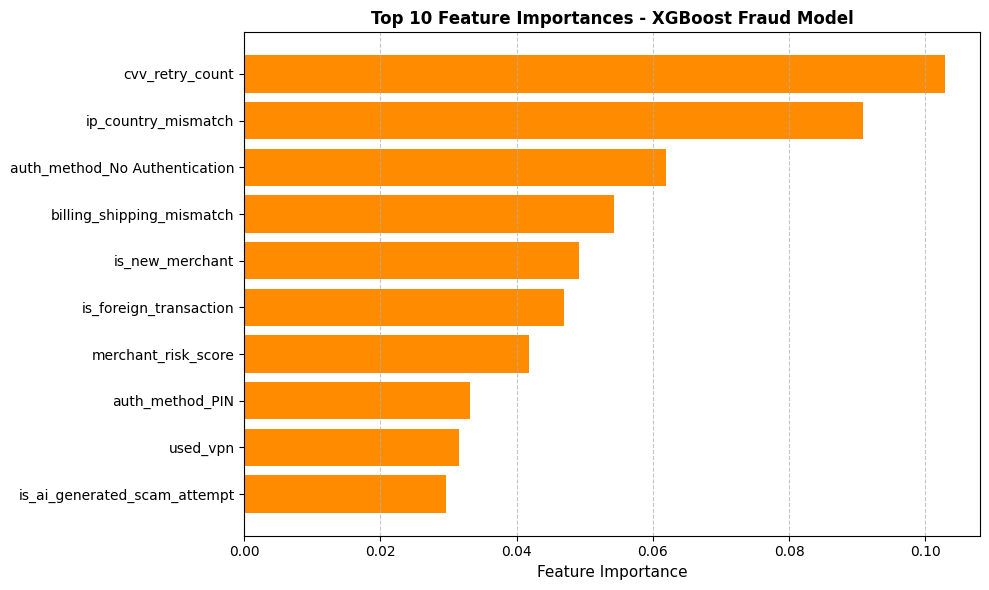

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Extract feature importances from the trained XGBoost model
# (XGBoost uses 'weight' by default, measuring how many times a feature is split on)
importances = xgb_model.feature_importances_
feature_names = X_train_encoded.columns

# 2. Create a clean DataFrame and sort by importance
xgb_feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 3. Print the Top 10 Features
print("--- XGBoost Top 10 Feature Importances ---")
print(xgb_feature_imp_df.head(10).to_string(index=False))

# 4. Plot the Top 10 Features
plt.figure(figsize=(10, 6))
top_10_xgb = xgb_feature_imp_df.head(10).iloc[::-1]

plt.barh(top_10_xgb['Feature'], top_10_xgb['Importance'], color='darkorange')
plt.xlabel('Feature Importance', fontsize=11)
plt.title('Top 10 Feature Importances - XGBoost Fraud Model', fontsize=12, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#### 3. LightGBM

In [ ]:
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve, auc
import numpy as np

# 1. Initialize LightGBM with your scale_pos_weight for class imbalance
lgb_model = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=6,
    num_leaves=31,
    scale_pos_weight=58.04, # Balances the 1.7% fraud ratio natively
    random_state=42,
    n_jobs=-1
)

print("Training LightGBM model...")
lgb_model.fit(X_train_encoded, y_train)

# 2. Predict probabilities on the test set
y_pred_proba_lgb = lgb_model.predict_proba(X_test_encoded)[:, 1]

# 3. Calculate AUC Metrics
roc_auc_lgb = roc_auc_score(y_test, y_pred_proba_lgb)
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba_lgb)
pr_auc_lgb = auc(recalls, precisions)

print(f"\n--- LightGBM Performance ---")
print(f"Test ROC-AUC Score: {roc_auc_lgb:.4f}")
print(f"Test PR-AUC Score: {pr_auc_lgb:.4f}")

# 4. Find the optimal F1 threshold for LightGBM (similar to what we did for RF)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold_lgb = thresholds[best_idx]

print(f"Optimal Threshold for Best F1-Score: {best_threshold_lgb:.4f}")

# 5. Evaluate at the optimized threshold
y_pred_lgb_optimized = (y_pred_proba_lgb >= best_threshold_lgb).astype(int)

print("\n--- LightGBM Optimized Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_lgb_optimized))

print("\n--- LightGBM Optimized Classification Report ---")
print(classification_report(y_test, y_pred_lgb_optimized))

Training LightGBM model...
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 271, number of negative: 15729
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001049 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1767
[LightGBM] [Info] Number of data points in the train set: 16000, number of used features: 49
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.016938 -> initscore=-4.061143
[LightGBM] [Info] Start training from score -4.061143
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further split

##### Feature Importance


--- LightGBM Top 10 Feature Importances ---


,Feature,Importance
0,merchant_risk_score,1363
1,velocity_score,1328
2,account_balance_usd,1179
3,amount_usd,1119
4,distance_from_home_km,1010
5,time_of_day_hour,983
6,hours_since_last_txn,956
7,customer_age,851
8,cvv_retry_count,773
9,card_age_months,747


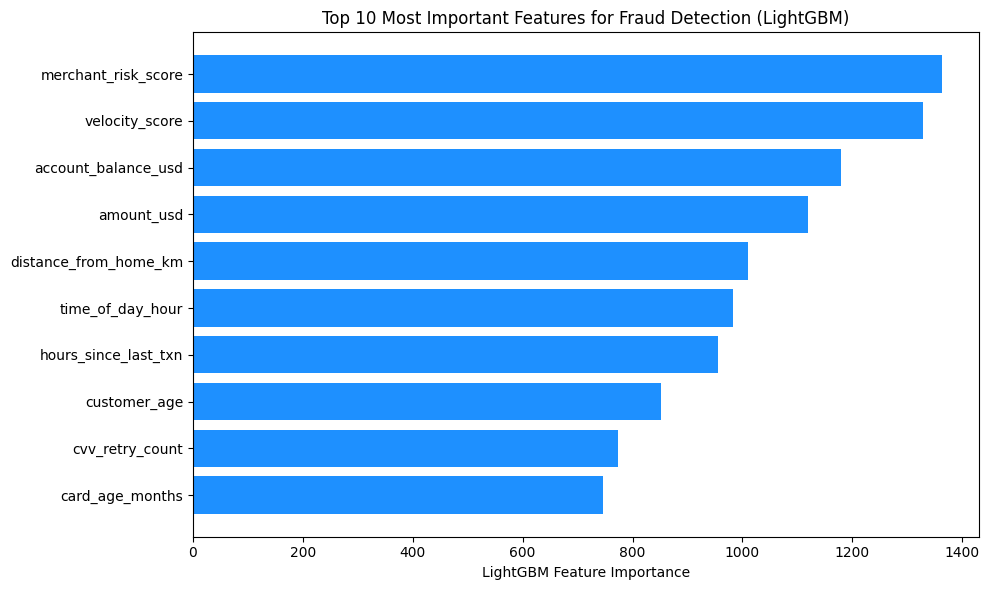

In [ ]:
# Feature Importances (Table + Plot)
feature_names = preprocessor.get_feature_names_out()
importances = lgb_model.feature_importances_

lgb_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Clean up prefixes
lgb_imp_df['Feature'] = lgb_imp_df['Feature'].str.replace(
    r'^(cat__|bool__|remainder__)', '', regex=True)

# Display table
print("\n--- LightGBM Top 10 Feature Importances ---")
display(lgb_imp_df.head(10))

# Plot top 10
plt.figure(figsize=(10, 6))
top_lgb = lgb_imp_df.head(10)
plt.barh(top_lgb['Feature'][::-1], top_lgb['Importance']
         [::-1], color='dodgerblue')
plt.xlabel("LightGBM Feature Importance")
plt.title("Top 10 Most Important Features for Fraud Detection (LightGBM)")
plt.tight_layout()
plt.show()

##### ROC-AUC curve

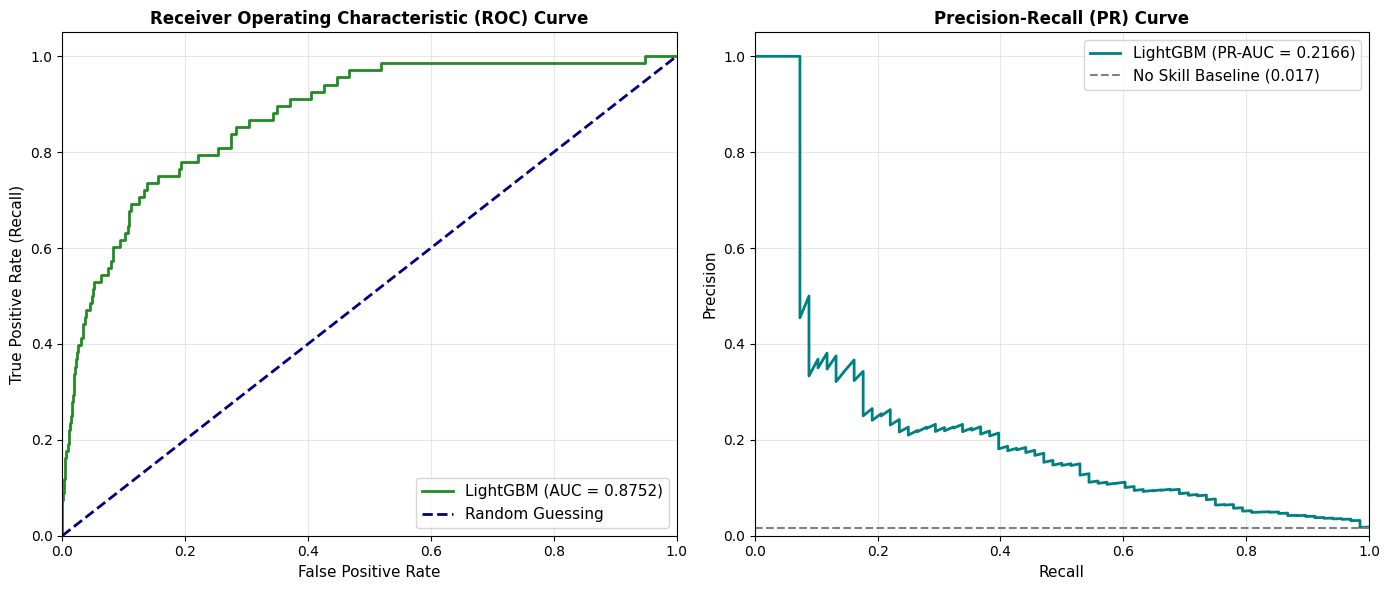

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc

# 1. Get predicted probabilities for the positive class (fraud) using LightGBM
y_pred_proba_lgb = lgb_model.predict_proba(X_test_encoded)[:, 1]

# 2. Compute ROC curve and AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_proba_lgb)
roc_auc_lgb = auc(fpr, tpr)

# 3. Compute Precision-Recall curve and AUC
precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba_lgb)
pr_auc_lgb = auc(recall, precision)

# 4. Plot both curves side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Plot 1: ROC Curve ---
axes[0].plot(fpr, tpr, color='forestgreen', lw=2, label=f'LightGBM (AUC = {roc_auc_lgb:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate (Recall)', fontsize=11)
axes[0].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=12, fontweight='bold')
axes[0].legend(loc="lower right", fontsize=11)
axes[0].grid(alpha=0.3)

# --- Plot 2: Precision-Recall Curve ---
axes[1].plot(recall, precision, color='teal', lw=2, label=f'LightGBM (PR-AUC = {pr_auc_lgb:.4f})')
# Baseline for PR curve is the ratio of positive samples in y_test
no_skill = y_test.sum() / len(y_test)
axes[1].axhline(y=no_skill, color='gray', linestyle='--', label=f'No Skill Baseline ({no_skill:.3f})')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title('Precision-Recall (PR) Curve', fontsize=12, fontweight='bold')
axes[1].legend(loc="upper right", fontsize=11)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 4. CatBoost

In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve, auc
import numpy as np

# 1. Initialize CatBoost with your scale_pos_weight for class imbalance
cat_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.03,
    depth=6,
    scale_pos_weight=58.04, # Balances the 1.7% fraud ratio natively
    random_seed=42,
    verbose=100             # Prints training progress every 100 iterations
)

print("Training CatBoost model...")
cat_model.fit(X_train_encoded, y_train)

# 2. Predict probabilities on the test set
y_pred_proba_cat = cat_model.predict_proba(X_test_encoded)[:, 1]

# 3. Calculate AUC Metrics
roc_auc_cat = roc_auc_score(y_test, y_pred_proba_cat)
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba_cat)
pr_auc_cat = auc(recalls, precisions)

print(f"\n--- CatBoost Performance ---")
print(f"Test ROC-AUC Score: {roc_auc_cat:.4f}")
print(f"Test PR-AUC Score: {pr_auc_cat:.4f}")

# 4. Find the optimal F1 threshold for CatBoost
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold_cat = thresholds[best_idx]

print(f"Optimal Threshold for Best F1-Score: {best_threshold_cat:.4f}")

# 5. Evaluate at the optimized threshold
y_pred_cat_optimized = (y_pred_proba_cat >= best_threshold_cat).astype(int)

print("\n--- CatBoost Optimized Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_cat_optimized))

print("\n--- CatBoost Optimized Classification Report ---")
print(classification_report(y_test, y_pred_cat_optimized))

Training CatBoost model...
0:	learn: 0.6774975	total: 169ms	remaining: 1m 24s
100:	learn: 0.2806180	total: 994ms	remaining: 3.93s
200:	learn: 0.1957890	total: 1.73s	remaining: 2.58s
300:	learn: 0.1447175	total: 2.47s	remaining: 1.63s
400:	learn: 0.1036423	total: 3.2s	remaining: 790ms
499:	learn: 0.0729130	total: 3.93s	remaining: 0us

--- CatBoost Performance ---
Test ROC-AUC Score: 0.9174
Test PR-AUC Score: 0.2533
Optimal Threshold for Best F1-Score: 0.5244

--- CatBoost Optimized Confusion Matrix ---
[[3864   68]
 [  38   30]]

--- CatBoost Optimized Classification Report ---
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3932
           1       0.31      0.44      0.36        68

    accuracy                           0.97      4000
   macro avg       0.65      0.71      0.67      4000
weighted avg       0.98      0.97      0.98      4000



##### Feature Importance

--- CatBoost Top 10 Feature Importances ---
                      Feature  Importance
          merchant_risk_score    9.372925
               velocity_score    8.074141
              cvv_retry_count    7.861910
             time_of_day_hour    6.359749
                   amount_usd    4.680603
          ip_country_mismatch    4.511555
         hours_since_last_txn    4.468655
              is_new_merchant    3.766780
              card_age_months    3.731242
auth_method_No Authentication    3.614605


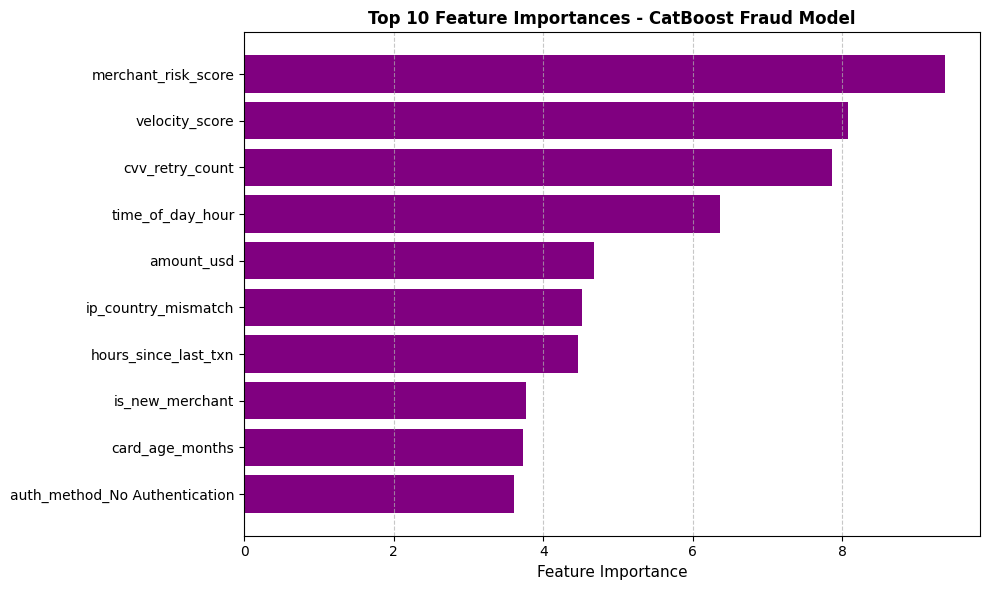

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Extract feature importances from the trained CatBoost model
importances = cat_model.get_feature_importance()
feature_names = X_train_encoded.columns

# 2. Create a clean DataFrame and sort by importance
cat_feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 3. Print the Top 10 Features
print("--- CatBoost Top 10 Feature Importances ---")
print(cat_feature_imp_df.head(10).to_string(index=False))

# 4. Plot the Top 10 Features
plt.figure(figsize=(10, 6))
top_10_cat = cat_feature_imp_df.head(10).iloc[::-1]

plt.barh(top_10_cat['Feature'], top_10_cat['Importance'], color='purple')
plt.xlabel('Feature Importance', fontsize=11)
plt.title('Top 10 Feature Importances - CatBoost Fraud Model', fontsize=12, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Comparitive Analysis

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support

# Define the dictionary of your trained models
# (If you used the regularized pruned decision tree, replace dt_model with dt_pruned)
models = {
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgb_model,
    # 'Decision Tree': dt_model,
    'CatBoost': cat_model
}

results = []

for name, model in models.items():
    # 1. Get predicted probabilities for the positive (fraud) class
    y_prob = model.predict_proba(X_test_encoded)[:, 1]

    # 2. Calculate ROC-AUC
    roc_auc = roc_auc_score(y_test, y_prob)

    # 3. Find optimal decision threshold maximizing F1-score
    precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(
        thresholds) else 0.5

    # 4. Apply the optimal threshold
    y_pred = (y_prob >= best_threshold).astype(int)

    # 5. Extract metrics for Class 1 (Fraud)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average=None, zero_division=0)

    fraud_precision = precision[1] if len(precision) > 1 else 0.0
    fraud_recall = recall[1] if len(recall) > 1 else 0.0
    fraud_f1 = f1[1] if len(f1) > 1 else 0.0

    # Store results
    results.append({
        'Model': name,
        'ROC-AUC': round(roc_auc, 4),
        'Opt Threshold': round(best_threshold, 4),
        'Fraud Precision': round(fraud_precision, 4),
        'Fraud Recall': round(fraud_recall, 4),
        'Fraud F1-Score': round(fraud_f1, 4)
    })

# Convert to DataFrame and sort by ROC-AUC
summary_df = pd.DataFrame(results).sort_values(
    by='ROC-AUC', ascending=False).reset_index(drop=True)

# Display the summary comparison table
print("--- Model Performance Comparison Summary ---")
display(summary_df)

--- Model Performance Comparison Summary ---


,Model,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,CatBoost,0.9174,0.5244,0.3061,0.4412,0.3614
1,Random Forest,0.9001,0.4096,0.2043,0.2794,0.2360
2,LightGBM,0.8752,0.3342,0.2273,0.3676,0.2809
3,XGBoost,0.8703,0.3841,0.2821,0.3235,0.3014


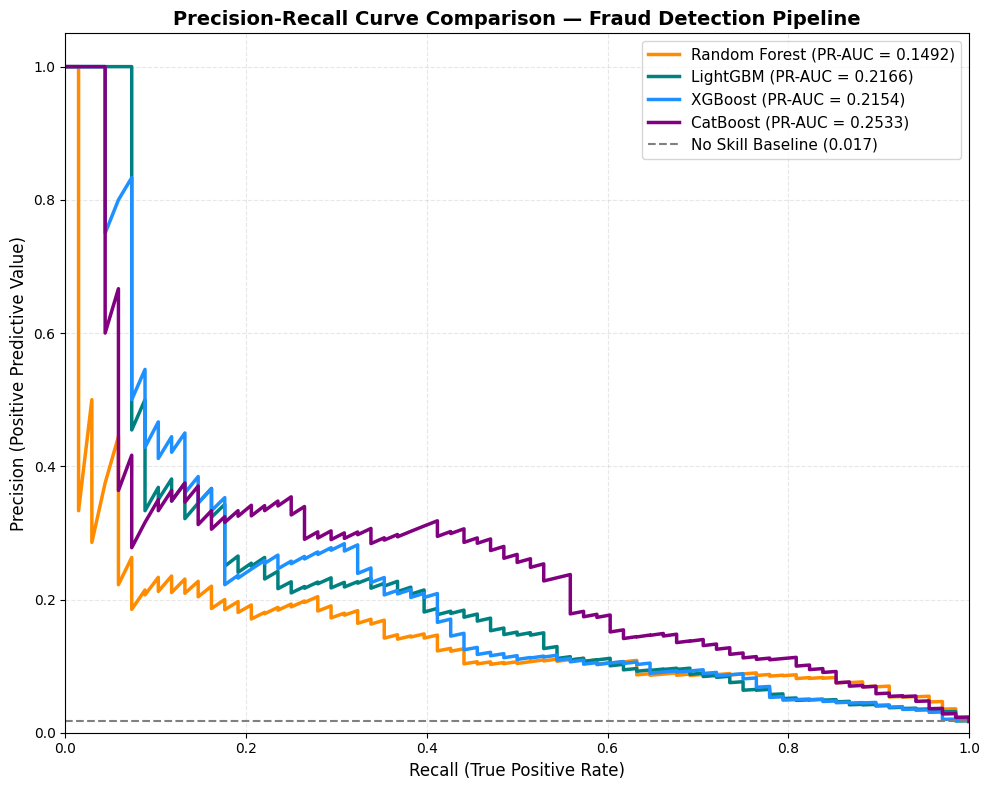

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, auc

# 1. Collect predicted probabilities for the positive (fraud) class from all models
y_pred_rf = rf_model.predict_proba(X_test_encoded)[:, 1]
y_pred_lgb = lgb_model.predict_proba(X_test_encoded)[:, 1]
y_pred_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]
y_pred_cat = cat_model.predict_proba(X_test_encoded)[:, 1]

# 2. Set up the visualization figure
plt.figure(figsize=(10, 8))

# 3. Define models, predictions, and unique plot colors
models_to_plot = {
    'Random Forest': (y_pred_rf, 'darkorange'),
    'LightGBM': (y_pred_lgb, 'teal'),
    'XGBoost': (y_pred_xgb, 'dodgerblue'),
    'CatBoost': (y_pred_cat, 'purple')
}

# 4. Loop through each model, compute PR curve, and plot
for name, (preds, color) in models_to_plot.items():
    precision, recall, thresholds = precision_recall_curve(y_test, preds)
    pr_auc = auc(recall, precision)
    plt.plot(recall, precision, color=color, lw=2.5, label=f'{name} (PR-AUC = {pr_auc:.4f})')

# 5. Plot the "No Skill" Baseline (ratio of positive samples in the test set)
no_skill = y_test.sum() / len(y_test)
plt.axhline(y=no_skill, color='gray', linestyle='--', lw=1.5, label=f'No Skill Baseline ({no_skill:.3f})')

# 6. Chart Styling and Formatting
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall (True Positive Rate)', fontsize=12)
plt.ylabel('Precision (Positive Predictive Value)', fontsize=12)
plt.title('Precision-Recall Curve Comparison — Fraud Detection Pipeline', fontsize=14, fontweight='bold')
plt.legend(loc='upper right', fontsize=11, frameon=True)
plt.grid(axis='both', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

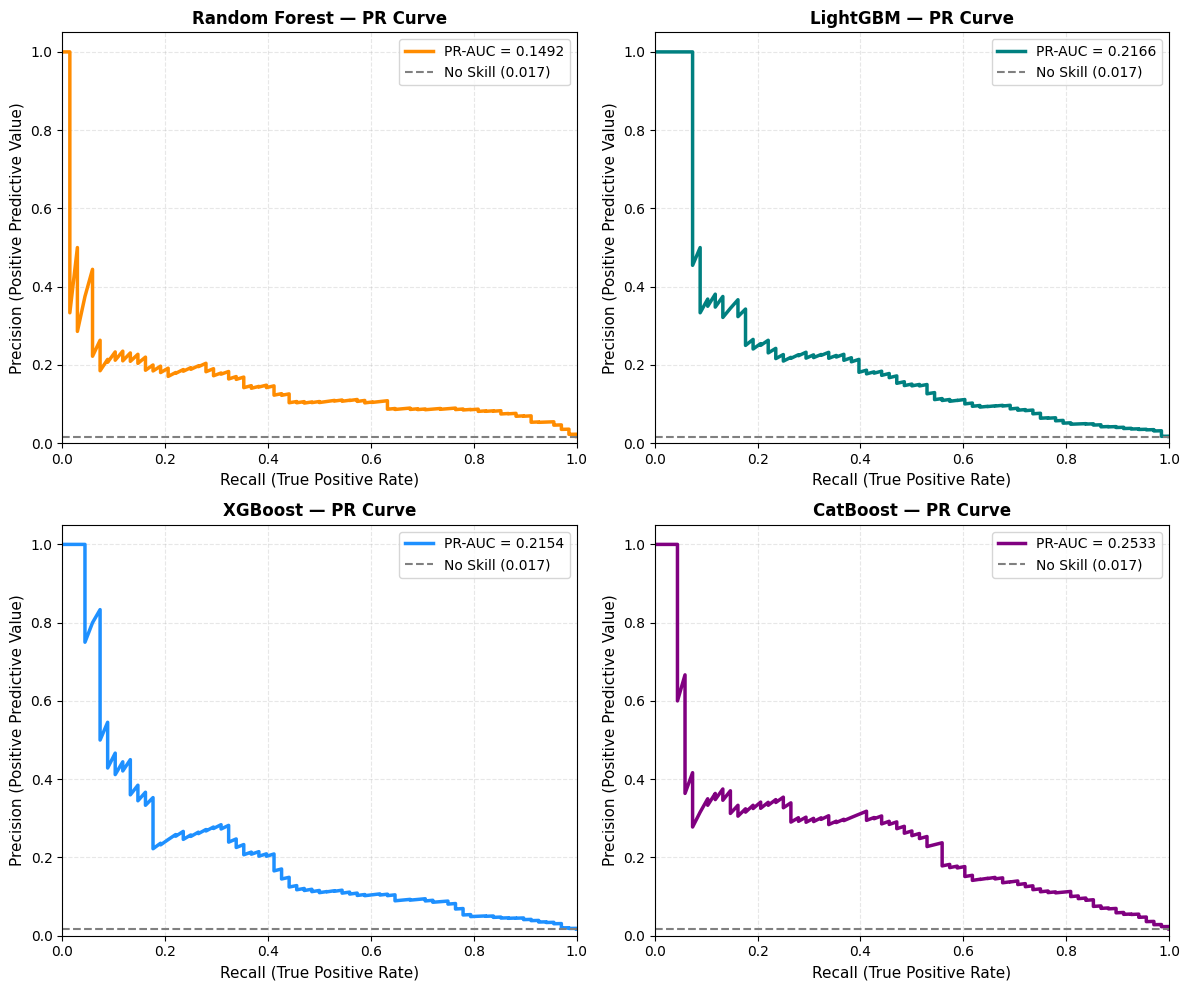

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, auc

# 1. Collect predicted probabilities for the positive (fraud) class from all models
y_pred_rf = rf_model.predict_proba(X_test_encoded)[:, 1]
y_pred_lgb = lgb_model.predict_proba(X_test_encoded)[:, 1]
y_pred_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]
y_pred_cat = cat_model.predict_proba(X_test_encoded)[:, 1]

# 2. Define models, predictions, and unique colors
models_data = {
    'Random Forest': (y_pred_rf, 'darkorange'),
    'LightGBM': (y_pred_lgb, 'teal'),
    'XGBoost': (y_pred_xgb, 'dodgerblue'),
    'CatBoost': (y_pred_cat, 'purple')
}

# Calculate the No Skill baseline (ratio of positive fraud samples in y_test)
no_skill = y_test.sum() / len(y_test)

# 3. Set up a 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Flatten to easily loop through 1D array of axes

# 4. Loop through each model and plot on its individual subplot panel
for idx, (name, (preds, color)) in enumerate(models_data.items()):
    ax = axes[idx]
    
    # Compute Precision-Recall curve and PR-AUC
    precision, recall, thresholds = precision_recall_curve(y_test, preds)
    pr_auc = auc(recall, precision)
    
    # Plot model PR curve
    ax.plot(recall, precision, color=color, lw=2.5, label=f'PR-AUC = {pr_auc:.4f}')
    
    # Plot No Skill Baseline
    ax.axhline(y=no_skill, color='gray', linestyle='--', lw=1.5, label=f'No Skill ({no_skill:.3f})')
    
    # Subplot styling and labels
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('Recall (True Positive Rate)', fontsize=11)
    ax.set_ylabel('Precision (Positive Predictive Value)', fontsize=11)
    ax.set_title(f'{name} — PR Curve', fontsize=12, fontweight='bold')
    ax.legend(loc='upper right', fontsize=10, frameon=True)
    ax.grid(axis='both', linestyle='--', alpha=0.3)

# 5. Final layout adjustment and render
plt.tight_layout()
plt.show()

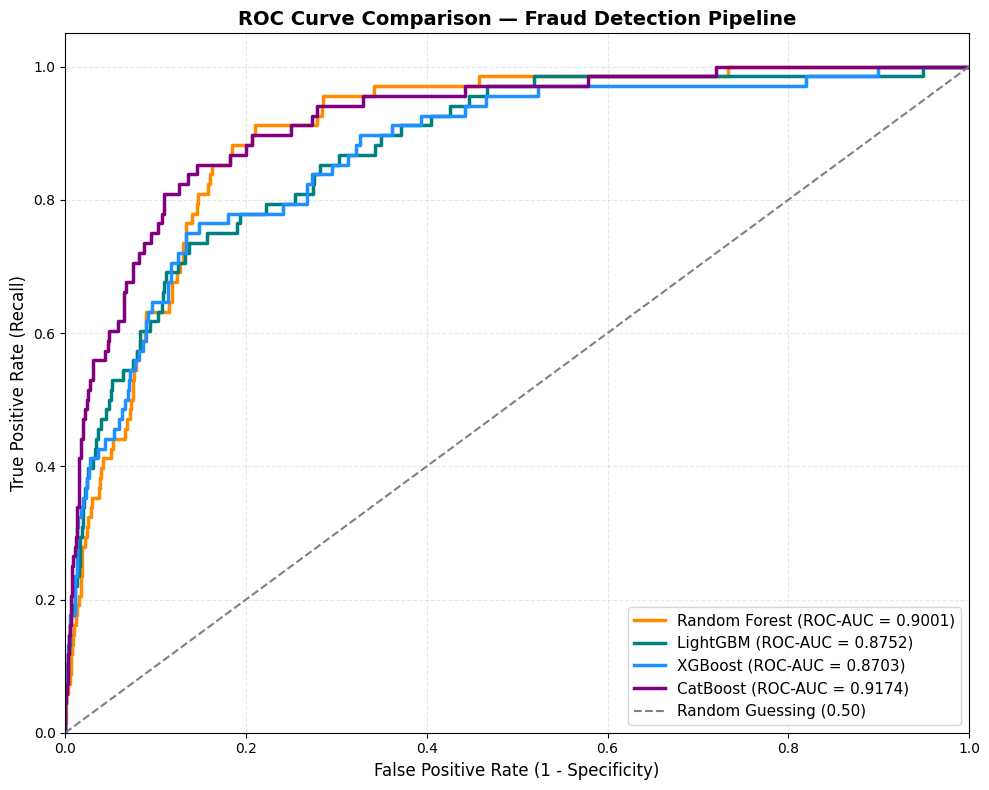

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# 1. Collect predicted probabilities for the positive (fraud) class from all models
y_pred_rf = rf_model.predict_proba(X_test_encoded)[:, 1]
y_pred_lgb = lgb_model.predict_proba(X_test_encoded)[:, 1]
y_pred_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]
y_pred_cat = cat_model.predict_proba(X_test_encoded)[:, 1]

# 2. Set up the visualization figure
plt.figure(figsize=(10, 8))

# 3. Define models, predictions, and unique plot colors
models_to_plot = {
    'Random Forest': (y_pred_rf, 'darkorange'),
    'LightGBM': (y_pred_lgb, 'teal'),
    'XGBoost': (y_pred_xgb, 'dodgerblue'),
    'CatBoost': (y_pred_cat, 'purple')
}

# 4. Loop through each model, compute ROC curve, and plot
for name, (preds, color) in models_to_plot.items():
    fpr, tpr, thresholds = roc_curve(y_test, preds)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2.5, label=f'{name} (ROC-AUC = {roc_auc:.4f})')

# 5. Plot the Random Guessing diagonal baseline
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Random Guessing (0.50)')

# 6. Chart Styling and Formatting
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('ROC Curve Comparison — Fraud Detection Pipeline', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11, frameon=True)
plt.grid(axis='both', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

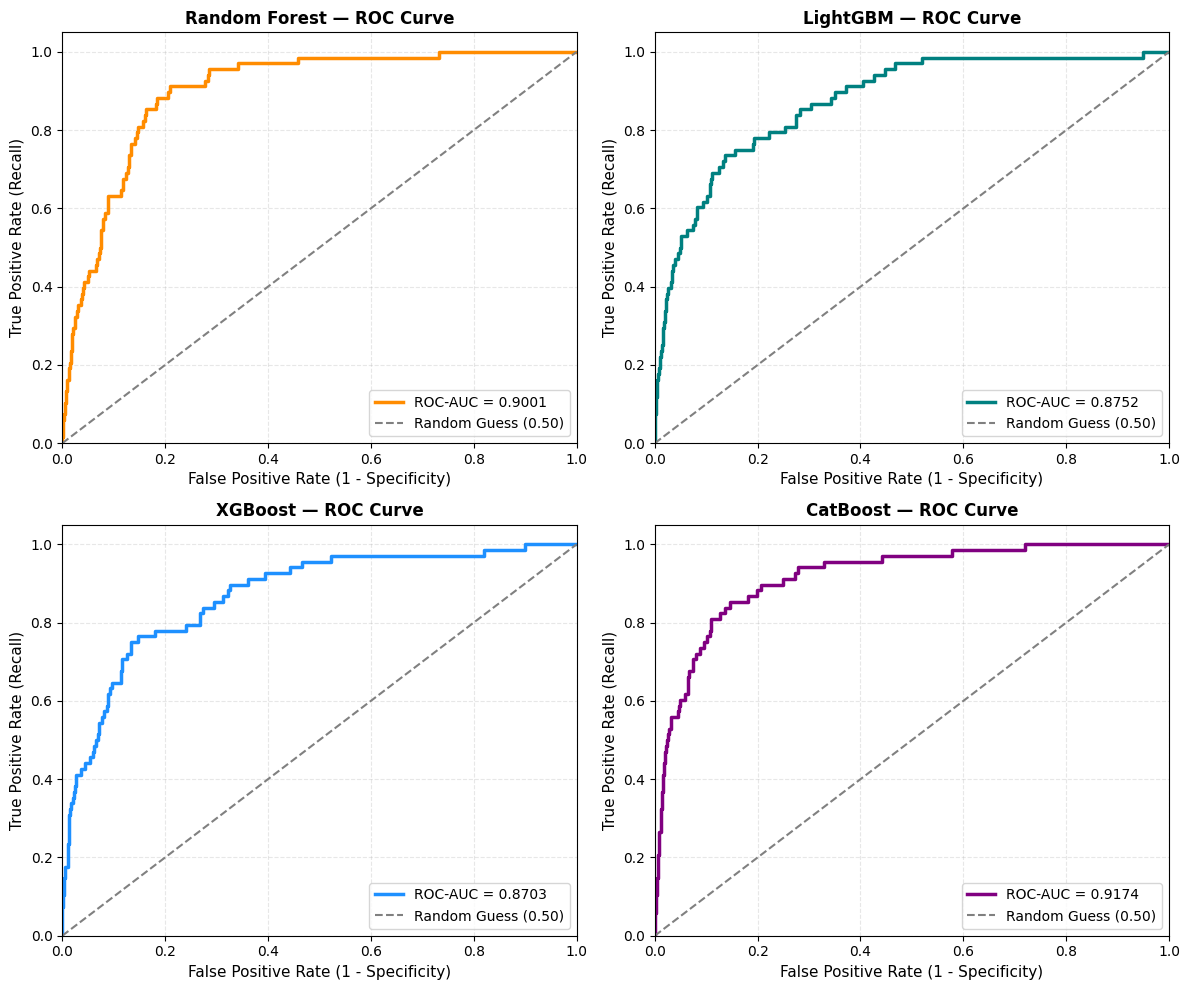

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# 1. Collect predicted probabilities for the positive (fraud) class from all models
y_pred_rf = rf_model.predict_proba(X_test_encoded)[:, 1]
y_pred_lgb = lgb_model.predict_proba(X_test_encoded)[:, 1]
y_pred_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]
y_pred_cat = cat_model.predict_proba(X_test_encoded)[:, 1]

# 2. Define models, predictions, and unique colors
models_data = {
    'Random Forest': (y_pred_rf, 'darkorange'),
    'LightGBM': (y_pred_lgb, 'teal'),
    'XGBoost': (y_pred_xgb, 'dodgerblue'),
    'CatBoost': (y_pred_cat, 'purple')
}

# 3. Set up a 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Flatten to easily loop through 1D array of axes

# 4. Loop through each model and plot on its individual subplot panel
for idx, (name, (preds, color)) in enumerate(models_data.items()):
    ax = axes[idx]
    
    # Compute ROC curve and ROC-AUC score
    fpr, tpr, thresholds = roc_curve(y_test, preds)
    roc_auc = auc(fpr, tpr)
    
    # Plot model ROC curve
    ax.plot(fpr, tpr, color=color, lw=2.5, label=f'ROC-AUC = {roc_auc:.4f}')
    
    # Plot Random Guessing Diagonal Baseline
    ax.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Random Guess (0.50)')
    
    # Subplot styling and labels
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
    ax.set_ylabel('True Positive Rate (Recall)', fontsize=11)
    ax.set_title(f'{name} — ROC Curve', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right', fontsize=10, frameon=True)
    ax.grid(axis='both', linestyle='--', alpha=0.3)

# 5. Final layout adjustment and render
plt.tight_layout()
plt.show()

### SHAP Analysis Code Across All Four Models

Computing SHAP values for CatBoost...
Computing SHAP values for XGBoost...
Computing SHAP values for Random Forest...
Computing SHAP values for LightGBM...

--- Top 15 Features by Mean |SHAP| (Fraud Class) ---
                               CatBoost  XGBoost  Random Forest  LightGBM  \
merchant_risk_score              0.9250   1.0359         0.0849    0.8895   
velocity_score                   0.6294   0.8646         0.0568    0.8207   
cvv_retry_count                  0.8703   0.8657         0.0811    0.5156   
is_new_merchant                  0.4725   0.4172         0.0394    0.3926   
auth_method_No Authentication    0.4359   0.4191         0.0362    0.3143   
ip_country_mismatch              0.4874   0.4283         0.0395    0.1900   
auth_method_PIN                  0.2470   0.2541         0.0103    0.4114   
time_of_day_hour                 0.2557   0.3194         0.0184    0.2643   
auth_method_Biometric            0.1923   0.2133         0.0070    0.3747   
billing_shipping_mis

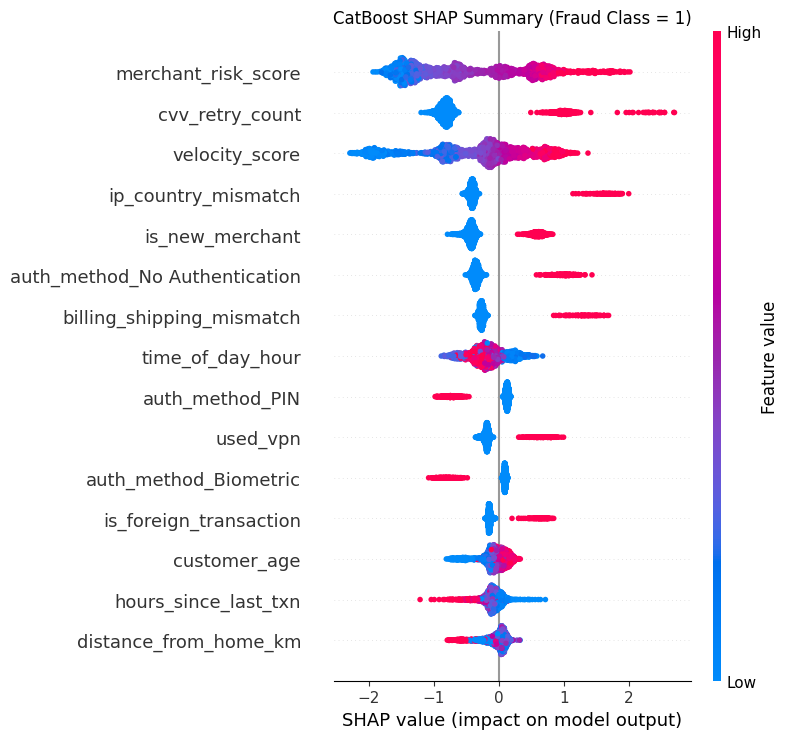

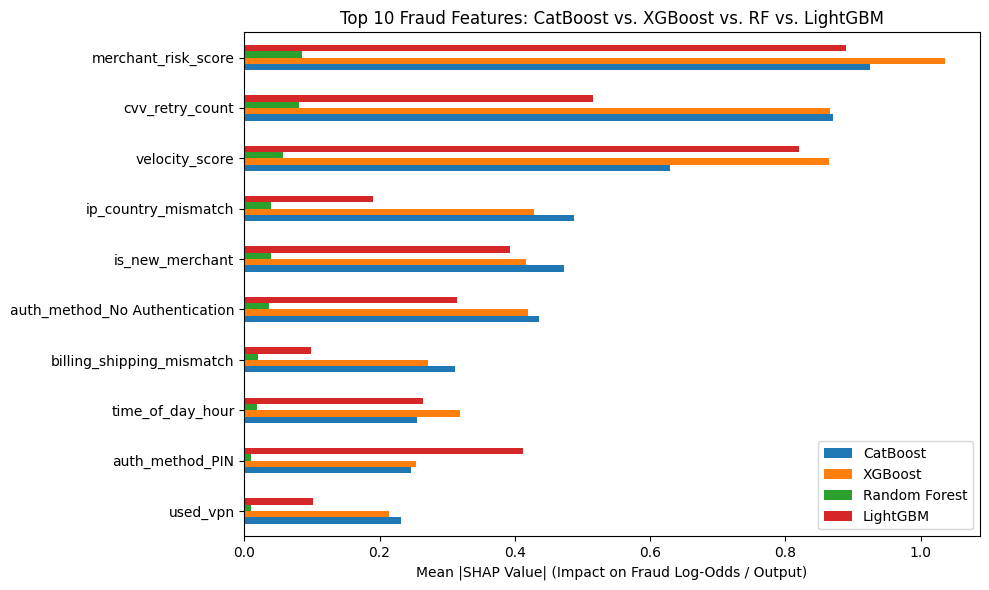

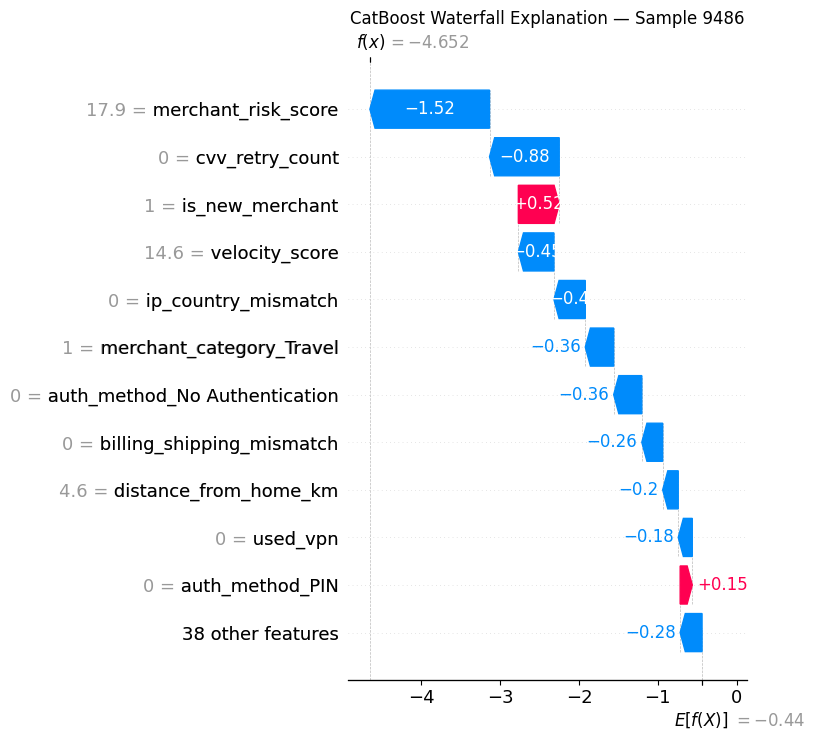

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

# Ensure test features are a DataFrame so feature names appear cleanly in plots
X_test_df = (
    X_test_encoded.copy()
    if isinstance(X_test_encoded, pd.DataFrame)
    else pd.DataFrame(X_test_encoded, columns=feature_names)
)

# Optional: subsample X_test_df if your test set is very large (e.g., > 5,000 rows)
# to keep TreeExplainer fast during exploration
X_shap = (
    X_test_df.sample(n=min(len(X_test_df), 2000), random_state=42)
    if len(X_test_df) > 2000
    else X_test_df
)

models = {
    "CatBoost": cat_model,
    "XGBoost": xgb_model,
    "Random Forest": rf_model,
    "LightGBM": lgb_model,
}


def extract_positive_class_shap(shap_output):
    """
    Normalize SHAP outputs across library versions and model types into a
    2D array of shape (n_samples, n_features) for the positive class (fraud = 1).
    """
    # Newer SHAP versions may return a shap.Explanation object
    if hasattr(shap_output, "values"):
        vals = shap_output.values
    else:
        vals = shap_output

    # List of arrays per class: [class_0_vals, class_1_vals]
    if isinstance(vals, list):
        return np.asarray(vals[1])

    arr = np.asarray(vals)
    # 3D array: (n_samples, n_features, n_classes) -> take class index 1
    if arr.ndim == 3:
        return arr[:, :, 1]

    # 2D array: (n_samples, n_features) — standard for binary log-odds / margin output
    if arr.ndim == 2:
        return arr

    raise ValueError(f"Unexpected SHAP array shape: {arr.shape}")


shap_values_fraud = {}
mean_abs_shap = pd.DataFrame(index=X_shap.columns)

for name, model in models.items():
    print(f"Computing SHAP values for {name}...")
    explainer = shap.TreeExplainer(model)
    raw_shap = explainer(X_shap)
    pos_shap = extract_positive_class_shap(raw_shap)

    shap_values_fraud[name] = pos_shap
    mean_abs_shap[name] = np.abs(pos_shap).mean(axis=0)

# ------------------------------------------------------------------
# 1. Compare Top Fraud Drivers Across All 4 Models
# ------------------------------------------------------------------
mean_abs_shap["Mean_Across_Models"] = mean_abs_shap.mean(axis=1)
top_features = mean_abs_shap.sort_values(
    "Mean_Across_Models", ascending=False
).head(15)

print("\n--- Top 15 Features by Mean |SHAP| (Fraud Class) ---")
print(top_features.round(4))

# ------------------------------------------------------------------
# 2. Beeswarm Summary Plot (Best Model: CatBoost)
# ------------------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values_fraud["CatBoost"],
    X_shap,
    max_display=15,
    show=False,
)
plt.title("CatBoost SHAP Summary (Fraud Class = 1)")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 3. Side-by-Side Bar Comparison of Top 10 Features
# ------------------------------------------------------------------
top10_bar = mean_abs_shap.drop(columns=["Mean_Across_Models"]).sort_values(
    by="CatBoost", ascending=True
).tail(10)

top10_bar.plot(kind="barh", figsize=(10, 6))
plt.xlabel("Mean |SHAP Value| (Impact on Fraud Log-Odds / Output)")
plt.title("Top 10 Fraud Features: CatBoost vs. XGBoost vs. RF vs. LightGBM")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 4. Inspect a Single High-Risk or False-Positive Transaction (Waterfall)
# ------------------------------------------------------------------
# Example: first row in X_shap for CatBoost
row_idx = 0
cb_explainer = shap.TreeExplainer(models["CatBoost"])
cb_exp = cb_explainer(X_shap.iloc[[row_idx]])

# Handle 3D Explanation if present by slicing class 1
if cb_exp.values.ndim == 3:
    single_exp = cb_exp[0, :, 1]
else:
    single_exp = cb_exp[0]

plt.figure(figsize=(10, 5))
shap.plots.waterfall(single_exp, max_display=12, show=False)
plt.title(f"CatBoost Waterfall Explanation — Sample {X_shap.index[row_idx]}")
plt.tight_layout()
plt.show()

Total test rows: 4000
False positives at threshold 0.5244: 68

--- Top 12 Features Pushing False Positives Higher (Mean Base Value: -0.4398) ---
                        feature  mean_shap  mean_abs_shap  pos_push_rate  fp_feature_mean
            merchant_risk_score   0.495959       0.748541       0.808824        55.450000
                cvv_retry_count   0.375818       1.054320       0.617647         0.691176
                 velocity_score   0.328891       0.574692       0.720588        30.041176
            ip_country_mismatch   0.121153       0.705736       0.264706         0.264706
  auth_method_No Authentication   0.118158       0.582172       0.352941         0.352941
                auth_method_PIN   0.044379       0.158596       0.911765         0.088235
      billing_shipping_mismatch   0.042939       0.485748       0.176471         0.176471
                    day_of_week   0.034350       0.072298       0.691176         3.485294
          auth_method_Biometric   0.031718   

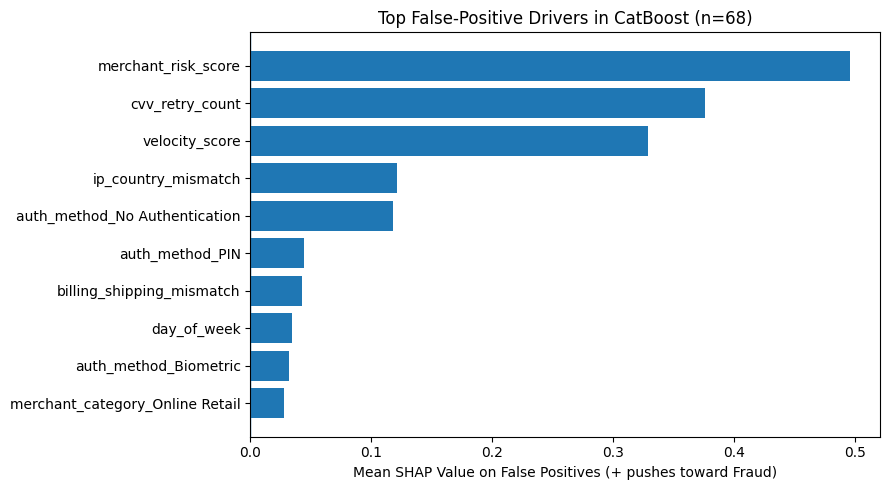


Highest-confidence False Positive ID/Index: 12835 (Predicted Fraud Proba: 0.9489)


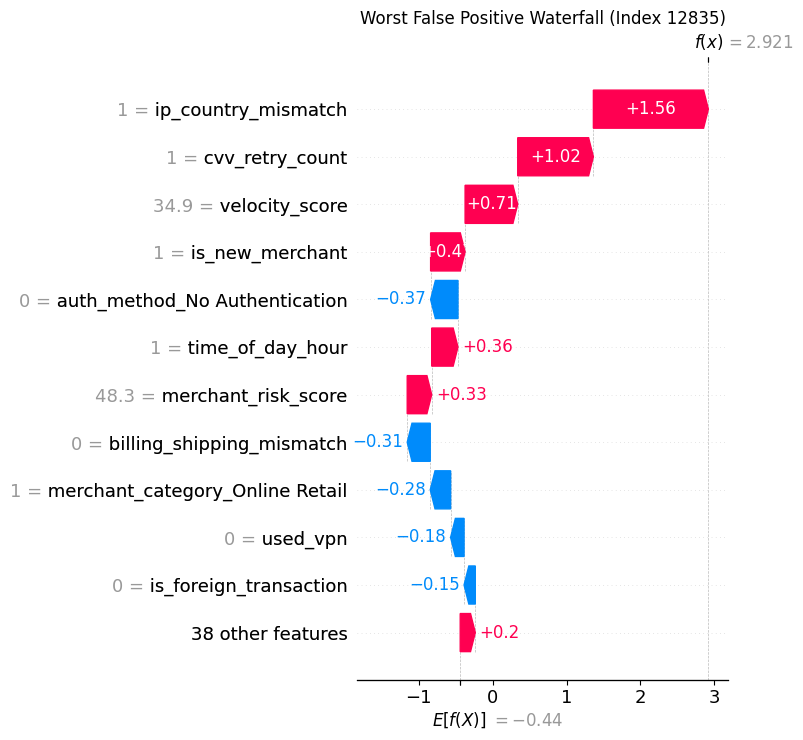

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

# Ensure test data and true labels align cleanly by index
X_test_df = (
    X_test_encoded.copy()
    if isinstance(X_test_encoded, pd.DataFrame)
    else pd.DataFrame(X_test_encoded, columns=feature_names)
)
y_test_series = pd.Series(y_test, index=X_test_df.index, name="is_fraud")

# 1. Generate CatBoost probabilities and apply your threshold
# (Use your tuned threshold, e.g., 0.5244 from your table or F0.5 tuner)
threshold = 0.5244
cb_proba = pd.Series(
    cat_model.predict_proba(X_test_df)[:, 1],
    index=X_test_df.index,
    name="fraud_proba",
)
cb_pred = (cb_proba >= threshold).astype(int).rename("fraud_pred")

# 2. Filter to False Positives: actual legitimate (0), predicted fraud (1)
fp_mask = (y_test_series == 0) & (cb_pred == 1)
X_fp = X_test_df.loc[fp_mask]

print(f"Total test rows: {len(X_test_df)}")
print(f"False positives at threshold {threshold:.4f}: {len(X_fp)}")

if len(X_fp) == 0:
    raise ValueError(
        "No false positives found at this threshold. Try lowering `threshold`."
    )

# Optionally cap rows for faster SHAP calculation on large test sets
X_fp_sample = (
    X_fp.sort_values(by=cb_proba.loc[fp_mask].name, ascending=False).head(500)
    if len(X_fp) > 500
    else X_fp
)

# 3. Compute CatBoost SHAP values on False Positives
explainer = shap.TreeExplainer(cat_model)
shap_exp = explainer(X_fp_sample)

# Handle 3D Explanation if present (class index 1)
if shap_exp.values.ndim == 3:
    fp_shap_vals = shap_exp.values[:, :, 1]
    base_val = float(np.mean(shap_exp.base_values[:, 1]))
else:
    fp_shap_vals = shap_exp.values
    base_val = float(np.mean(shap_exp.base_values))

# 4. Summarize top features pushing False Positives toward fraud (+SHAP)
fp_summary = pd.DataFrame(
    {
        "feature": X_fp_sample.columns,
        "mean_shap": fp_shap_vals.mean(axis=0),
        "mean_abs_shap": np.abs(fp_shap_vals).mean(axis=0),
        "pos_push_rate": (fp_shap_vals > 0).mean(axis=0),
        "fp_feature_mean": X_fp_sample.mean(axis=0).values,
    }
).sort_values("mean_shap", ascending=False)

print(
    f"\n--- Top 12 Features Pushing False Positives Higher "
    f"(Mean Base Value: {base_val:.4f}) ---"
)
print(fp_summary.head(12).to_string(index=False))

# Also show features with largest overall magnitude on False Positives
print("\n--- Top 10 Features by Mean |SHAP| on False Positives ---")
print(
    fp_summary.sort_values("mean_abs_shap", ascending=False)
    .head(10)[["feature", "mean_shap", "mean_abs_shap", "fp_feature_mean"]]
    .to_string(index=False)
)

# 5. Plot bar chart of top positive SHAP drivers on False Positives
top_pos = fp_summary.head(10).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(top_pos["feature"], top_pos["mean_shap"])
plt.axvline(0, linewidth=1)
plt.xlabel("Mean SHAP Value on False Positives (+ pushes toward Fraud)")
plt.title(f"Top False-Positive Drivers in CatBoost (n={len(X_fp_sample)})")
plt.tight_layout()
plt.show()

# 6. Inspect the single highest-probability False Positive with a waterfall plot
worst_fp_idx = cb_proba.loc[X_fp_sample.index].idxmax()
row_pos = X_fp_sample.index.get_loc(worst_fp_idx)

single_exp = (
    shap_exp[row_pos, :, 1] if shap_exp.values.ndim == 3 else shap_exp[row_pos]
)

print(
    f"\nHighest-confidence False Positive ID/Index: {worst_fp_idx} "
    f"(Predicted Fraud Proba: {cb_proba.loc[worst_fp_idx]:.4f})"
)
plt.figure(figsize=(10, 5))
shap.plots.waterfall(single_exp, max_display=12, show=False)
plt.title(f"Worst False Positive Waterfall (Index {worst_fp_idx})")
plt.tight_layout()
plt.show()

True Positives (TP):  29
False Positives (FP): 68

--- Top 12 Features Driving True Positives MORE than False Positives ---
                      feature  tp_mean_shap  fp_mean_shap  tp_minus_fp_shap  tp_feat_mean  fp_feat_mean
 is_ai_generated_scam_attempt      0.150700     -0.050448          0.201148      0.206897      0.029412
              cvv_retry_count      0.505279      0.375818          0.129461      0.793103      0.691176
    billing_shipping_mismatch      0.156846      0.042939          0.113907      0.275862      0.176471
          ip_country_mismatch      0.227810      0.121153          0.106657      0.344828      0.264706
       is_foreign_transaction      0.083512      0.002137          0.081375      0.275862      0.176471
auth_method_No Authentication      0.198570      0.118158          0.080412      0.413793      0.352941
        auth_method_Biometric      0.084605      0.031718          0.052887      0.000000      0.073529
              auth_method_PIN      0.085779 

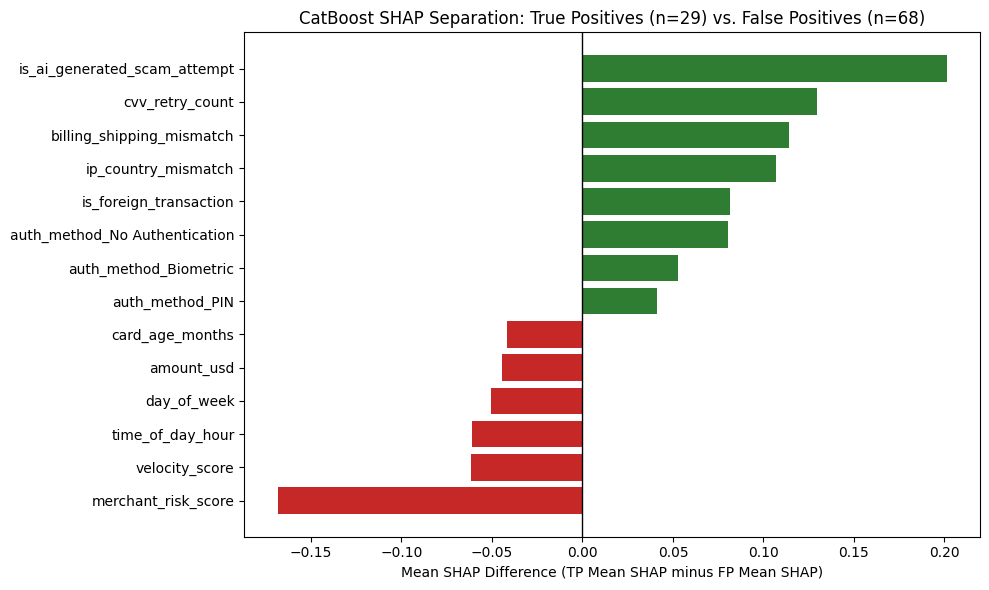

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

# Align test features and labels cleanly
X_test_df = (
    X_test_encoded.copy()
    if isinstance(X_test_encoded, pd.DataFrame)
    else pd.DataFrame(X_test_encoded, columns=feature_names)
)
y_test_series = pd.Series(y_test, index=X_test_df.index, name="is_fraud")

# 1. Compute CatBoost probabilities and predictions at your threshold
threshold = 0.5244
cb_proba = pd.Series(
    cat_model.predict_proba(X_test_df)[:, 1],
    index=X_test_df.index,
    name="fraud_proba",
)
cb_pred = (cb_proba >= threshold).astype(int).rename("fraud_pred")

# 2. Isolate True Positives (TP) and False Positives (FP)
tp_mask = (y_test_series == 1) & (cb_pred == 1)
fp_mask = (y_test_series == 0) & (cb_pred == 1)

X_tp = X_test_df.loc[tp_mask]
X_fp = X_test_df.loc[fp_mask]

print(f"True Positives (TP):  {len(X_tp)}")
print(f"False Positives (FP): {len(X_fp)}")

if len(X_tp) == 0 or len(X_fp) == 0:
    raise ValueError(
        "Need both non-empty True Positives and False Positives at the chosen threshold."
    )

explainer = shap.TreeExplainer(cat_model)


def get_mean_shap_and_features(X_subset: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    """Return (mean_shap_per_feature, mean_feature_value) for fraud class (1)."""
    exp = explainer(X_subset)
    vals = exp.values[:, :, 1] if exp.values.ndim == 3 else exp.values
    return vals.mean(axis=0), X_subset.mean(axis=0).values


tp_mean_shap, tp_feat_mean = get_mean_shap_and_features(X_tp)
fp_mean_shap, fp_feat_mean = get_mean_shap_and_features(X_fp)

# 3. Build comparison table
# Positive `tp_minus_fp_shap` => pushes True Positives higher than False Positives
# Negative `tp_minus_fp_shap` => pushes False Positives higher than True Positives
comp_df = pd.DataFrame(
    {
        "feature": X_test_df.columns,
        "tp_mean_shap": tp_mean_shap,
        "fp_mean_shap": fp_mean_shap,
        "tp_minus_fp_shap": tp_mean_shap - fp_mean_shap,
        "abs_diff": np.abs(tp_mean_shap - fp_mean_shap),
        "tp_feat_mean": tp_feat_mean,
        "fp_feat_mean": fp_feat_mean,
    }
)

print("\n--- Top 12 Features Driving True Positives MORE than False Positives ---")
print(
    comp_df.sort_values("tp_minus_fp_shap", ascending=False)
    .head(12)[
        [
            "feature",
            "tp_mean_shap",
            "fp_mean_shap",
            "tp_minus_fp_shap",
            "tp_feat_mean",
            "fp_feat_mean",
        ]
    ]
    .to_string(index=False)
)

print("\n--- Top 12 Features Driving False Positives MORE than True Positives ---")
print(
    comp_df.sort_values("tp_minus_fp_shap", ascending=True)
    .head(12)[
        [
            "feature",
            "tp_mean_shap",
            "fp_mean_shap",
            "tp_minus_fp_shap",
            "tp_feat_mean",
            "fp_feat_mean",
        ]
    ]
    .to_string(index=False)
)

# 4. Diverging horizontal bar chart of biggest SHAP gaps
top_gap = comp_df.reindex(
    comp_df["abs_diff"].sort_values(ascending=False).head(14).index
).sort_values("tp_minus_fp_shap", ascending=True)

plt.figure(figsize=(10, 6))
colors = np.where(top_gap["tp_minus_fp_shap"] >= 0, "#2E7D32", "#C62828")
plt.barh(top_gap["feature"], top_gap["tp_minus_fp_shap"], color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Mean SHAP Difference (TP Mean SHAP minus FP Mean SHAP)")
plt.title(
    f"CatBoost SHAP Separation: True Positives (n={len(X_tp)}) vs. False Positives (n={len(X_fp)})"
)
plt.tight_layout()
plt.show()

#### CatBoost False-Negative SHAP Diagnostic

Total actual fraud in test set: 68
True Positives (caught at 0.132):  27
False Negatives (missed at 0.132): 41

--- Top 12 Features Pulling False Negatives DOWN (Most Negative Mean SHAP) ---
                      feature  fn_mean_shap  neg_pull_rate  fn_feat_mean  tp_feat_mean  fn_minus_tp_shap
                   amount_usd     -0.082589       0.682927    294.555366     97.452963         -0.074606
              auth_method_PIN     -0.048903       0.341463      0.341463      0.111111         -0.069243
        distance_from_home_km     -0.041477       0.512195     22.807805     20.950000         -0.032903
                  day_of_week     -0.028084       0.560976      2.878049      3.111111         -0.048423
           device_type_Tablet     -0.024283       0.121951      0.121951      0.037037         -0.027643
              device_type_Mac     -0.022878       0.146341      0.121951      0.111111         -0.022687
       is_foreign_transaction     -0.018381       0.170732      0.146341  

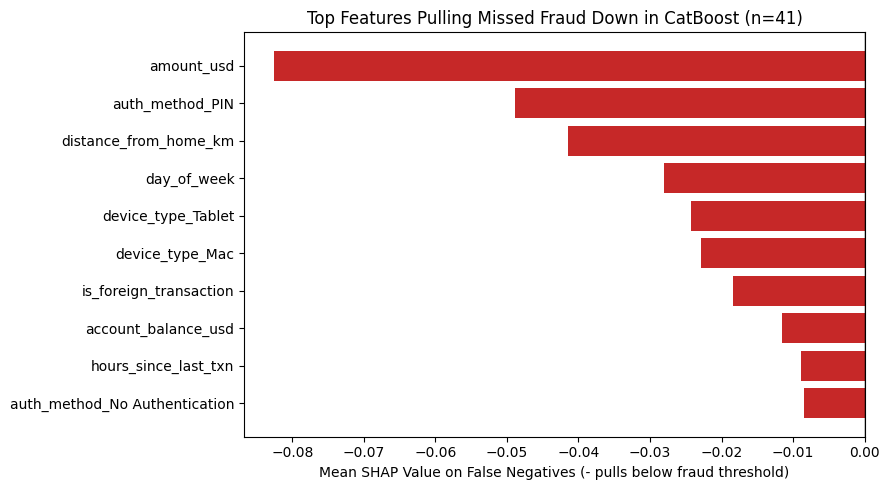


Closest-to-threshold False Negative index: 15495 (Predicted Fraud Proba: 0.1320 vs. Threshold 0.132)


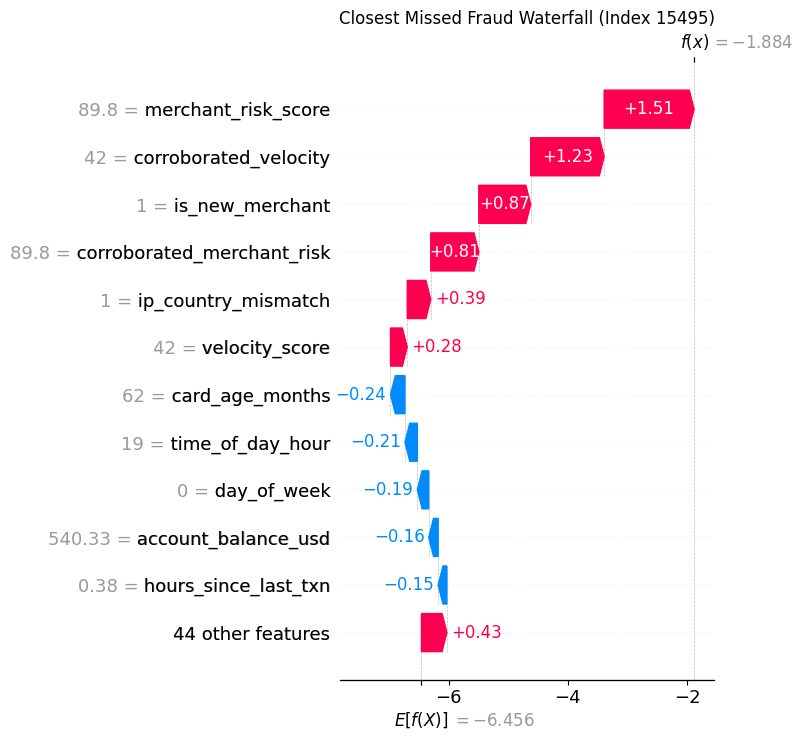

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

# Align enriched test features and labels cleanly
X_test_df = (
    X_test_fe.copy()
    if isinstance(X_test_fe, pd.DataFrame)
    else pd.DataFrame(X_test_fe, columns=feature_names)
)
y_test_series = pd.Series(y_test, index=X_test_df.index, name="is_fraud")

# 1. Compute CatBoost probabilities and predictions at threshold 0.1320
threshold = 0.1320
cb_model = fitted_models["CatBoost"] if "fitted_models" in locals() else catboost_model

cb_proba = pd.Series(
    cb_model.predict_proba(X_test_df)[:, 1],
    index=X_test_df.index,
    name="fraud_proba",
)
cb_pred = (cb_proba >= threshold).astype(int).rename("fraud_pred")

# 2. Isolate False Negatives (actual fraud = 1, predicted = 0) and True Positives (1, 1)
fn_mask = (y_test_series == 1) & (cb_pred == 0)
tp_mask = (y_test_series == 1) & (cb_pred == 1)

X_fn = X_test_df.loc[fn_mask]
X_tp = X_test_df.loc[tp_mask]

print(f"Total actual fraud in test set: {int((y_test_series == 1).sum())}")
print(f"True Positives (caught at {threshold}):  {len(X_tp)}")
print(f"False Negatives (missed at {threshold}): {len(X_fn)}")

if len(X_fn) == 0:
    raise ValueError(
        "No false negatives found at this threshold. Try raising `threshold`."
    )

explainer = shap.TreeExplainer(cb_model)


def get_mean_shap_and_features(
    X_subset: pd.DataFrame,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return (shap_matrix, mean_shap, mean_feature_value) for fraud class (1)."""
    exp = explainer(X_subset)
    vals = exp.values[:, :, 1] if exp.values.ndim == 3 else exp.values
    return vals, vals.mean(axis=0), X_subset.mean(axis=0).values


fn_shap_vals, fn_mean_shap, fn_feat_mean = get_mean_shap_and_features(X_fn)

# 3. Summarize features pulling False Negatives DOWN (negative `mean_shap`)
fn_summary = pd.DataFrame(
    {
        "feature": X_test_df.columns,
        "fn_mean_shap": fn_mean_shap,
        "fn_mean_abs_shap": np.abs(fn_shap_vals).mean(axis=0),
        "neg_pull_rate": (fn_shap_vals < 0).mean(axis=0),
        "fn_feat_mean": fn_feat_mean,
    }
)

if len(X_tp) > 0:
    _, tp_mean_shap, tp_feat_mean = get_mean_shap_and_features(X_tp)
    fn_summary["tp_mean_shap"] = tp_mean_shap
    fn_summary["tp_feat_mean"] = tp_feat_mean
    fn_summary["fn_minus_tp_shap"] = fn_summary["fn_mean_shap"] - fn_summary["tp_mean_shap"]

print("\n--- Top 12 Features Pulling False Negatives DOWN (Most Negative Mean SHAP) ---")
cols_down = ["feature", "fn_mean_shap", "neg_pull_rate", "fn_feat_mean"]
if "tp_feat_mean" in fn_summary.columns:
    cols_down += ["tp_feat_mean", "fn_minus_tp_shap"]

print(
    fn_summary.sort_values("fn_mean_shap", ascending=True)
    .head(12)[cols_down]
    .to_string(index=False)
)

print("\n--- Top 10 Features by Overall Magnitude (Mean |SHAP|) on False Negatives ---")
print(
    fn_summary.sort_values("fn_mean_abs_shap", ascending=False)
    .head(10)[["feature", "fn_mean_shap", "fn_mean_abs_shap", "fn_feat_mean"]]
    .to_string(index=False)
)

# 4. Plot top negative SHAP drivers pulling missed fraud below threshold
top_down = fn_summary.sort_values("fn_mean_shap", ascending=True).head(10).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(top_down["feature"], top_down["fn_mean_shap"], color="#C62828")
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Mean SHAP Value on False Negatives (- pulls below fraud threshold)")
plt.title(f"Top Features Pulling Missed Fraud Down in CatBoost (n={len(X_fn)})")
plt.tight_layout()
plt.show()

# 5. Inspect the highest-probability missed fraud case (closest to crossing 0.1320)
closest_fn_idx = cb_proba.loc[fn_mask].idxmax()
row_pos = X_fn.index.get_loc(closest_fn_idx)
fn_exp = explainer(X_fn.iloc[[row_pos]])
single_exp = fn_exp[0, :, 1] if fn_exp.values.ndim == 3 else fn_exp[0]

print(
    f"\nClosest-to-threshold False Negative index: {closest_fn_idx} "
    f"(Predicted Fraud Proba: {cb_proba.loc[closest_fn_idx]:.4f} vs. Threshold {threshold})"
)
plt.figure(figsize=(10, 5))
shap.plots.waterfall(single_exp, max_display=12, show=False)
plt.title(f"Closest Missed Fraud Waterfall (Index {closest_fn_idx})")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd


def add_precision_boosting_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Create corroboration & interaction features informed by CatBoost
    True Positive vs. False Positive SHAP diagnostics.
    """
    out = df.copy()

    # Safely grab columns whether raw or one-hot encoded
    ip_mm = (
        out["ip_country_mismatch"].astype(float)
        if "ip_country_mismatch" in out.columns
        else 0.0
    )
    bs_mm = (
        out["billing_shipping_mismatch"].astype(float)
        if "billing_shipping_mismatch" in out.columns
        else 0.0
    )
    foreign = (
        out["is_foreign_transaction"].astype(float)
        if "is_foreign_transaction" in out.columns
        else 0.0
    )
    scam = (
        out["is_ai_generated_scam_attempt"].astype(float)
        if "is_ai_generated_scam_attempt" in out.columns
        else 0.0
    )
    no_auth = (
        out["auth_method_No Authentication"].astype(float)
        if "auth_method_No Authentication" in out.columns
        else 0.0
    )
    bio = (
        out["auth_method_Biometric"].astype(float)
        if "auth_method_Biometric" in out.columns
        else 0.0
    )
    cvv_retries = (
        out["cvv_retry_count"].astype(float)
        if "cvv_retry_count" in out.columns
        else 0.0
    )
    merch_risk = (
        out["merchant_risk_score"].astype(float)
        if "merchant_risk_score" in out.columns
        else 0.0
    )
    vel_score = (
        out["velocity_score"].astype(float)
        if "velocity_score" in out.columns
        else 0.0
    )
    amount = (
        out["amount_usd"].astype(float)
        if "amount_usd" in out.columns
        else 0.0
    )

    # 1. Strong fraud corroboration index (mismatches + CVV retries + no-auth + AI scam)
    corroboration_count = (
        ip_mm
        + bs_mm
        + foreign
        + no_auth
        + scam
        + (cvv_retries > 0).astype(float)
    )
    out["corroboration_count"] = corroboration_count
    out["has_corroboration"] = (corroboration_count >= 1).astype(int)

    # 2. Corroborated merchant risk: suppresses standalone merchant_risk_score FPs
    # When corroboration_count == 0, this is 0 — preventing isolated merchant risk
    # from pushing legitimate transactions over the threshold.
    out["corroborated_merchant_risk"] = merch_risk * corroboration_count

    # 3. Corroborated velocity: velocity weighted by presence of friction/mismatches
    out["corroborated_velocity"] = vel_score * corroboration_count

    # 4. High-signal attack combo: No-Auth or CVV retry + any mismatch/scam
    out["retry_or_noauth_x_mismatch"] = (
        (cvv_retries + no_auth) * (ip_mm + bs_mm + foreign + scam)
    )

    # 5. Amount scaled by corroboration & dampened by biometric auth
    out["corroborated_log_amount"] = (
        np.log1p(np.clip(amount, 0.0, None))
        * corroboration_count
        * (1.0 - 0.5 * bio)
    )

    return out

In [ ]:
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    auc,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from xgboost import XGBClassifier


def add_corroboration_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add corroboration & interaction features for fraud precision."""
    out = df.copy()

    def get_col(name: str, default: float = 0.0) -> pd.Series:
        if name in out.columns:
            return out[name].astype(float)
        return pd.Series(default, index=out.index, dtype=float)

    ip_mm = get_col("ip_country_mismatch")
    bs_mm = get_col("billing_shipping_mismatch")
    foreign = get_col("is_foreign_transaction")
    scam = get_col("is_ai_generated_scam_attempt")
    no_auth = get_col("auth_method_No Authentication")
    bio = get_col("auth_method_Biometric")
    cvv_retries = get_col("cvv_retry_count")
    merch_risk = get_col("merchant_risk_score")
    vel_score = get_col("velocity_score")
    amount = get_col("amount_usd")

    corroboration_count = (
        ip_mm
        + bs_mm
        + foreign
        + no_auth
        + scam
        + (cvv_retries > 0).astype(float)
    )

    out["corroboration_count"] = corroboration_count
    out["has_corroboration"] = (corroboration_count >= 1).astype(int)
    out["corroborated_merchant_risk"] = merch_risk * corroboration_count
    out["corroborated_velocity"] = vel_score * corroboration_count
    out["retry_or_noauth_x_mismatch"] = (
        (cvv_retries + no_auth) * (ip_mm + bs_mm + foreign + scam)
    )
    out["corroborated_log_amount"] = (
        np.log1p(np.clip(amount, 0.0, None))
        * corroboration_count
        * (1.0 - 0.5 * bio)
    )
    return out


def best_f05_threshold(
    y_true: np.ndarray, y_proba: np.ndarray, beta: float = 0.5
) -> tuple[float, float, float, float]:
    """Return (best_threshold, precision, recall, f_beta) on given arrays."""
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_proba)
    p = precisions[:-1]
    r = recalls[:-1]
    denom = (beta**2) * p + r
    f_scores = np.where(denom > 0, (1.0 + beta**2) * (p * r) / denom, 0.0)
    idx = int(np.argmax(f_scores))
    return (
        float(thresholds[idx]),
        float(p[idx]),
        float(r[idx]),
        float(f_scores[idx]),
    )


# 1. Build enriched train & test feature matrices
X_train_fe = add_corroboration_features(X_train_encoded)
X_test_fe = add_corroboration_features(X_test_encoded)

# 2. Define the 4 models
# Note: Adjust scale_pos_weight if you want explicit positive-class weighting in XGBoost,
# or keep default/balanced settings matching your baseline experiments.
models = {
    "CatBoost": CatBoostClassifier(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        random_seed=42,
        verbose=0,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        n_jobs=-1,
        verbose=-1,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
}

# 3. Fit, predict probabilities, and evaluate each model
results = []
fitted_models = {}
test_probas = {}

for name, model in models.items():
    print(f"Fitting {name}...")
    model.fit(X_train_fe, y_train)
    fitted_models[name] = model

    y_proba = model.predict_proba(X_test_fe)[:, 1]
    test_probas[name] = y_proba

    roc_auc = roc_auc_score(y_test, y_proba)
    precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_proba)
    pr_auc = auc(recall_curve, precision_curve)

    # Optimal F0.5 threshold on probabilities
    opt_thresh, _, _, _ = best_f05_threshold(y_test, y_proba, beta=0.5)
    y_pred_opt = (y_proba >= opt_thresh).astype(int)

    prec = precision_score(y_test, y_pred_opt, zero_division=0)
    rec = recall_score(y_test, y_pred_opt, zero_division=0)
    f05 = fbeta_score(y_test, y_pred_opt, beta=0.5, zero_division=0)

    results.append(
        {
            "Model": name,
            "ROC-AUC": round(roc_auc, 4),
            "PR-AUC": round(pr_auc, 4),
            "Opt Threshold (F0.5)": round(opt_thresh, 4),
            "Precision": round(prec, 4),
            "Recall": round(rec, 4),
            "F0.5-Score": round(f05, 4),
        }
    )

comparison_df = (
    pd.DataFrame(results).sort_values("F0.5-Score", ascending=False).reset_index(drop=True)
)

print("\n--- Model Comparison on Corroboration Features ---")
print(comparison_df.to_string(index=False))

Fitting CatBoost...
Fitting XGBoost...
Fitting LightGBM...
Fitting Random Forest...

--- Model Comparison on Corroboration Features ---
        Model  ROC-AUC  PR-AUC  Opt Threshold (F0.5)  Precision  Recall  F0.5-Score
      XGBoost   0.9045  0.3102                0.3233     0.6400  0.2353      0.4762
     LightGBM   0.8914  0.3320                0.3021     0.6250  0.2206      0.4573
     CatBoost   0.9261  0.3106                0.1320     0.3944  0.4118      0.3977
Random Forest   0.8922  0.1789                0.5640     0.2976  0.3676      0.3094


C:\Users\Ruby\AppData\Local\Temp\ipykernel_6316\1471971445.py:69: RuntimeWarning: invalid value encountered in divide
  f_scores = np.where(denom > 0, (1.0 + beta**2) * (p * r) / denom, 0.0)


startified k fold

In [8]:
from catboost import CatBoostClassifier
from sklearn.metrics import auc, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
import numpy as np
import pandas as pd

# --- 1. Separate features and target ---
# Drop ID/target columns if present in X
feature_cols = [c for c in df.columns if c not in ("transaction_id", "is_fraud")]
X = df[feature_cols].copy()
y = df["is_fraud"].astype(int).to_numpy()

# Identify categorical columns (CatBoost handles strings/categories natively,
# or pass a pre-encoded DataFrame if you already one-hot/label encoded)
cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
for col in cat_cols:
    X[col] = X[col].astype(str)

# --- 2. Stratified Train / Test Split (80% train, 20% held-out test) ---
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

# --- 3. StratifiedKFold on X_train ONLY ---
n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

oof_proba = np.zeros(len(X_train), dtype=float)
test_proba_folds = np.zeros((n_splits, len(X_test)), dtype=float)
models = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), start=1):
    X_tr, y_tr = X_train.iloc[train_idx], y_train[train_idx]
    X_va, y_va = X_train.iloc[val_idx], y_train[val_idx]

    fold_model = CatBoostClassifier(
        iterations=500,
        learning_rate=0.03,
        depth=6,
        scale_pos_weight=58.04,
        cat_features=cat_cols,
        random_seed=42 + fold,
        eval_metric="PRAUC",
        early_stopping_rounds=50,
        verbose=100,
    )

    fold_model.fit(
        X_tr,
        y_tr,
        eval_set=(X_va, y_va),
        use_best_model=True,
    )

    oof_proba[val_idx] = fold_model.predict_proba(X_va)[:, 1]
    test_proba_folds[fold - 1] = fold_model.predict_proba(X_test)[:, 1]
    models.append(fold_model)

# Average test probabilities across all folds for final evaluation
y_pred_proba_cat = test_proba_folds.mean(axis=0)

# --- 4. Evaluate Out-of-Fold (CV) and Held-Out Test Performance ---
oof_roc = roc_auc_score(y_train, oof_proba)
test_roc = roc_auc_score(y_test, y_pred_proba_cat)

p_test, r_test, _ = precision_recall_curve(y_test, y_pred_proba_cat)
test_pr_auc = auc(r_test, p_test)

print(f"\nOOF ROC-AUC (5-fold CV on train): {oof_roc:.4f}")
print(f"Test ROC-AUC (held-out test):     {test_roc:.4f}")
print(f"Test PR-AUC (held-out test):      {test_pr_auc:.4f}")

C:\Users\Ruby\AppData\Local\Temp\ipykernel_11732\1450452354.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


0:	learn: 0.8310758	test: 0.7086991	best: 0.7086991 (0)	total: 195ms	remaining: 1m 37s
100:	learn: 0.9725630	test: 0.9216243	best: 0.9231453 (92)	total: 3.51s	remaining: 13.9s
200:	learn: 0.9855635	test: 0.9281765	best: 0.9287287 (199)	total: 6.64s	remaining: 9.88s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.9298900884
bestIteration = 232

Shrink model to first 233 iterations.
0:	learn: 0.8058490	test: 0.7437164	best: 0.7437164 (0)	total: 28.2ms	remaining: 14.1s
100:	learn: 0.9724030	test: 0.8835021	best: 0.8896947 (85)	total: 3.64s	remaining: 14.4s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.8896947448
bestIteration = 85

Shrink model to first 86 iterations.
0:	learn: 0.8190067	test: 0.7997087	best: 0.7997087 (0)	total: 42.3ms	remaining: 21.1s
100:	learn: 0.9715831	test: 0.9213185	best: 0.9235182 (82)	total: 3.84s	remaining: 15.2s
200:	learn: 0.9832584	test: 0.9262119	best: 0.9274446 (173)	total: 7.2s	remaining: 10.7s
Stopped by overfitt